In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "16"

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Arc
import matplotlib.patheffects as pe
import pickle
import seaborn as sns
import sklearn
import torch
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
import statsmodels

import sys
sys.path.append('2D_gastruloids_v5')
import fns_plotting_scripts as fns_plot
import fns_NN
import IIF_analysis as IIF

import importlib
importlib.reload(IIF);
importlib.reload(fns_plot);

import matplotlib.colors as mcolors
import warnings
from sklearn.exceptions import InconsistentVersionWarning
import time
import matplotlib.colors as mcolors

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

In [9]:
# LOAD DATA 

file_suffix = '.png'

#data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250716.csv', index_col=0)
dataDir = '/Users/idse/data_tmp/signaldecoding/data_BMPdoses/data'
data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250509.csv', index_col=0) # '/expZ2_normalized_signals_251024.csv')
data.index.name = None
data.rename(columns={'SOX17_1': 'SOX17'}, inplace=True)
data.rename(columns={'DAPI_1': 'DAPI'}, inplace=True)

# SPECIFY METADATA

tol = {'DAPI':[1,99],'ISL1':[1,99],'TFAP2C':[1,99],'SOX17':[1,99],'TBXT':[1,99],'SOX2':[1,99],'NANOG':[1,99],'TBX6':[1,99],'SMAD23':[1,99]};
#conditions = list(np.unique(data['condition']))
conditions = ['B50','B200','B10']

#thresh = {'ISL1': 800, 'GATA3': 786, 'HAND1': 790, 'CDX2': 742, 'TFAP2C': 656, 'SOX17': 550, 'PRDM1': 600, 'NANOG': 1500, 'TBX6': 300, 'TBXT': 352, 'MIXL1': 427, 'EOMES': 225, 'SNAI1': 342, 'OCT4': 649, 'SOX2': 924, 'OTX2': 420} # 'FOXA2': 620, 
thresh = {'ISL1': 500, 'GATA3': 700, 'HAND1': 500, 'CDX2': 600, 'TFAP2C': 600, 'SOX17': 500, 'PRDM1': 650, 'NANOG': 1600, 'TBX6': 375, 'TBXT': 285, 'MIXL1': 400, 'EOMES': 200, 'SNAI1': 300, 'OCT4': 500, 'SOX2': 400, 'OTX2': 400}

gene_names = ['ISL1', 'GATA3', 'HAND1', 'CDX2', 'TFAP2C', 'SOX17', 'PRDM1', 'SNAI1', 'MIXL1', 'EOMES', 'TBXT', 'TBX6', 'OCT4', 'NANOG','SOX2', 'OTX2']# 'FOXA2',
markers = list(thresh.keys())
signal_names = ['pSMAD1','ncYAP','BCat','LEF1','ncSMAD2','ncSMAD23','cytopERK','cytopAKT']
signal_names_simplified = ['pSMAD1','YAP','β-cat', 'LEF1', 'SMAD2','SMAD2/3','pERK','pAKT']
signal_names_images = ['pSMAD1','YAP','BCat', 'LEF1', 'SMAD2','SMAD23','pERK','pAKT']
clean_signal_names = dict(zip(signal_names,signal_names_simplified))
feature_names = ['nucArea', 'nucVolume','nucMajorAxis', 'nucMinorAxis', 'nucCircularity', 'CircleEdgeDist','RadialDist']


# remove a few rows of bad data, reindex
mask = data[signal_names + gene_names].isna() | (data[signal_names + gene_names] < 0)
mask = mask.any(axis=1)
print(np.sum(mask))
data = data[~mask]
data.index = range(0, len(data))

meta = IIF.Metadata();
meta.xres = 0.325;
meta.yres = 0.325;
meta.channels = signal_names+gene_names;
meta.conditions = conditions;

9


In [8]:
cond = 'B50'
data_cond = data[data['condition']==cond]

## Graph of mutual informations

In [9]:
# mutual information between signals

N_signals = len(signal_names)
MIsigs = np.zeros((N_signals, N_signals))

for si in range(N_signals):
    
    MIsigs[si,si] = np.nan
    
    for sj in range(si+1, N_signals):
        MIsigs[si,sj] = fns_plot.calc_MI_sklearn(data_cond[signal_names[si]].to_numpy(), data_cond[signal_names[sj]].to_numpy())
        MIsigs[sj,si] = MIsigs[si,sj]

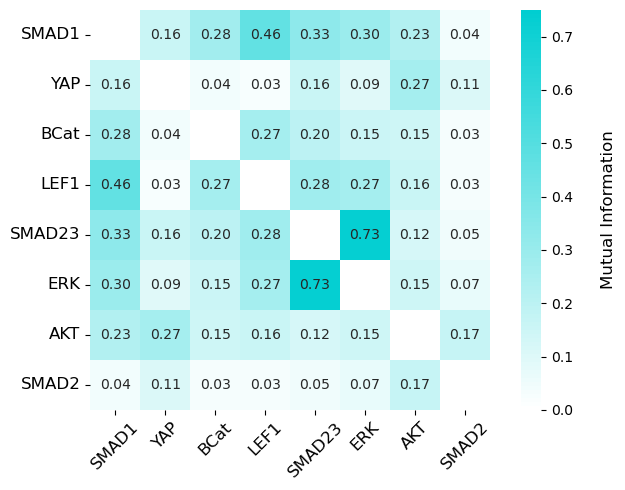

In [10]:
colors = ['white', 'darkturquoise']
n_bins = 100
fs = 12
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)

plt.figure(figsize=(7, 5))

ax = sns.heatmap(MIsigs, annot=True, cmap=cmap, vmin=0, vmax=0.75, square=True, fmt='.2f')
ax.set_xticklabels(signal_names_simplified, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Mutual Information', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig("FigS4/" + 'MI_MIheatmap' + '_sig2sig' + cond + file_suffix)

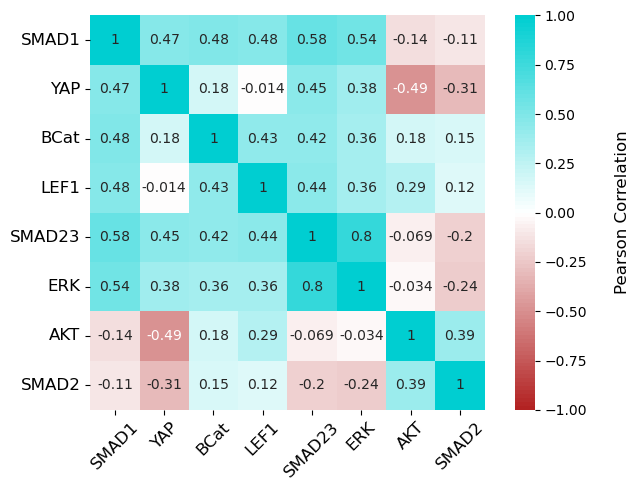

In [11]:
# correlation between signals

plt.figure(figsize=(7, 5))
sigs = data_cond[signal_names]
colors = ['firebrick', 'white', 'darkturquoise']
n_bins = 100
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)


ax = sns.heatmap(sigs.corr(), annot=True, cmap=cmap, vmin=-1, vmax=1, square=True)
ax.set_xticklabels(signal_names_simplified, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Pearson Correlation', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig("FigS4/" + 'MI_corrheatmap' + '_sig2sig' + cond + file_suffix)

In [12]:
# mutual information between signals and fate markers

N_signals = len(signal_names)
N_genes = len(gene_names)
MI = np.zeros((N_signals, N_genes))

for si in range(N_signals):
    for fj in range(N_genes):
        MI[si,fj] = fns_plot.calc_MI_sklearn(data_cond[signal_names[si]].to_numpy(), data_cond[gene_names[fj]].to_numpy())

MI = pd.DataFrame(MI, index=signal_names, columns=gene_names)
allcorr = data_cond[signal_names + gene_names].corr()

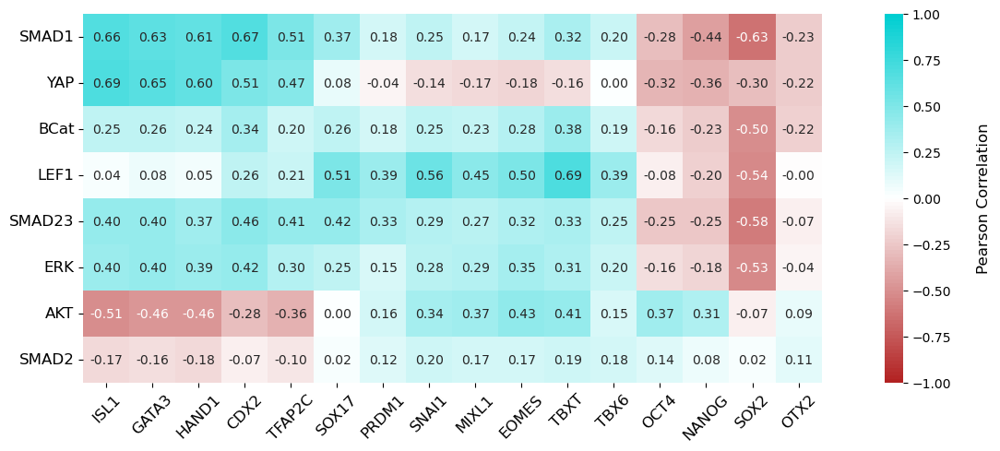

In [13]:
colors = ['firebrick','white', 'darkturquoise']
n_bins = 100
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)

plt.figure(figsize=(14, 5))

ax = sns.heatmap(allcorr.loc[signal_names, gene_names], annot=True, cmap=cmap, vmin=-1, vmax=1, square=True, fmt='.2f')
ax.set_xticklabels(gene_names, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Pearson Correlation', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig("FigS4/" + 'MI_corrheatmap' + '_sig2fate' + cond + file_suffix)

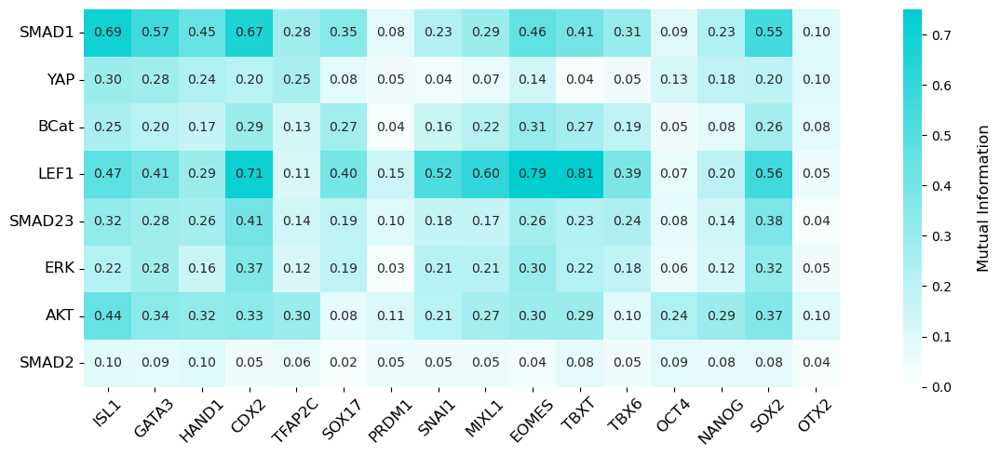

In [14]:
colors = ['white', 'darkturquoise']
n_bins = 100
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)

plt.figure(figsize=(14, 5))

ax = sns.heatmap(MI, annot=True, cmap=cmap, vmin=0, vmax=0.75, square=True, fmt='.2f')
ax.set_xticklabels(gene_names, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Mutual Information', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig("FigS4/" + 'MI_MIheatmap' + '_sig2fate' + cond + file_suffix)

ERROR! Session/line number was not unique in database. History logging moved to new session 1120


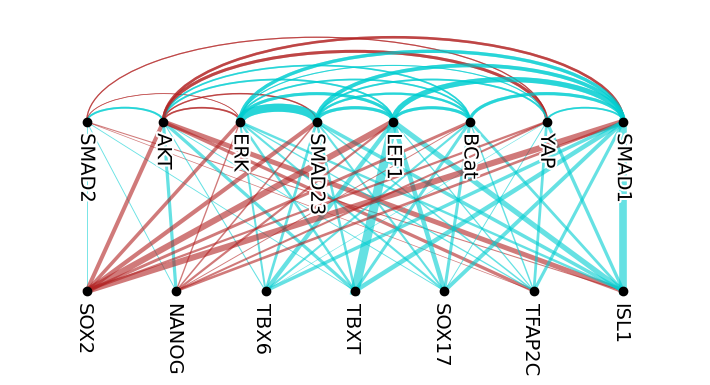

In [16]:
importlib.reload(IIF);

mygenes = ['ISL1', 'TFAP2C', 'SOX17', 'TBXT', 'TBX6', 'NANOG', 'SOX2']
fig, ax = plt.subplots(figsize=(max(len(signal_names), len(mygenes))*0.9, 4))

IIF.plotMIgraph(dataDir, data, cond, signal_names, mygenes, signames_clean=signal_names_simplified, rotate=True, ax=ax, fs=14);

## Bar graphs of cumulative MI

In [247]:
# get unique MI in each signal (MI - MI of all signals except one)
importlib.reload(IIF);

# RUN MODEL FOR ALL SIGNALS EXCEPT ONE
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
N_run = 5
signal_combinations = [signal_names]
for n in range(len(signal_names)):
    signal_combinations.append(signal_names[:n] + signal_names[n+1:])

preds = {}
data_B50 = data[data['condition']=='B50']

for signals in signal_combinations:

    sig_str = '_'.join(sorted(signals))

    if os.path.exists(dataDir + '/Fig3_VIB/Fig3_VIB_' + sig_str + '_B50predonly_forMI.csv'):
        print(f'loading: {sig_str}')
        pred_mean_df = pd.read_csv(dataDir + '/Fig3_VIB/Fig3_VIB_' + sig_str + '_B50predonly_forMI.csv', index_col=0)

    else:
        print(f'calculating: {sig_str}')
        pred_mean_df, _ = IIF.sig2fate(data_B50, signals, gene_names, N_run, hyperparam)
        pred_mean_df.to_csv(dataDir + '/Fig3_VIB/Fig3_VIB_' + sig_str + '_B50predonly_forMI.csv')

    preds[sig_str] = pred_mean_df

# CALCULATE MI
colonies = [int(n) for n in np.unique(data_B50['Colony'])]
MI_dec = {}
genelist = mygenes

for f in genelist:

    MI_dec[f] = pd.DataFrame(np.zeros((len(preds.keys()),len(colonies))), index=preds.keys(), columns=colonies)

    for ci in colonies:
        idx = data['Colony']==ci
    
        for s in preds.keys():
            MI_dec[f].at[s,ci] = sklearn.feature_selection.mutual_info_regression(preds[s].loc[idx,f].to_numpy().reshape(-1, 1), data.loc[idx,f].to_numpy())/np.log(2)

MI_uniques = []

# GET UNIQUE PART
for f in mygenes:
    
    MI_unique = MI_dec[f].mean(axis=1).iloc[0] - MI_dec[f].mean(axis=1) 
    MI_unique = MI_unique.iloc[1:]#/MI_dec[f].std(axis=1).iloc[0]
    MI_unique[MI_unique < 0] = 0
    MI_unique.index = signal_names
    MI_unique['total'] = MI_dec[f].mean(axis=1).iloc[0]
    MI_unique = MI_unique.to_frame(name=f)
    MI_uniques.append(MI_unique)

MI_uniques = pd.concat(MI_uniques, axis=1)

calculating: BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1
  Run 0/5
Elapsed time: 58.371567726135254 seconds
  Run 1/5
Elapsed time: 57.81597852706909 seconds
  Run 2/5
Elapsed time: 54.69820499420166 seconds
  Run 3/5
Elapsed time: 54.364909410476685 seconds
  Run 4/5
Elapsed time: 56.49741268157959 seconds
calculating: BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP
  Run 0/5
Elapsed time: 59.076600074768066 seconds
  Run 1/5
Elapsed time: 57.14530944824219 seconds
  Run 2/5
Elapsed time: 55.606359004974365 seconds
  Run 3/5
Elapsed time: 54.62387013435364 seconds
  Run 4/5
Elapsed time: 55.154672384262085 seconds
calculating: BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_pSMAD1
  Run 0/5
Elapsed time: 56.391910791397095 seconds
  Run 1/5
Elapsed time: 56.6323516368866 seconds
  Run 2/5
Elapsed time: 55.17188310623169 seconds
  Run 3/5
Elapsed time: 56.785229444503784 seconds
  Run 4/5
Elapsed time: 57.43611264228821 seconds
calculating: LEF1_cytopAKT_cytopERK_ncSMAD2_

ERROR! Session/line number was not unique in database. History logging moved to new session 1127
==========ISL1====================
rd: 1
250509_Exp20/251115_VIB_1D_B50_pSMAD1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncYAP_avg.csv
250509_Exp20/251115_VIB_1D_B50_BCat_avg.csv
250509_Exp20/251115_VIB_1D_B50_LEF1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD2_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD23_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopERK_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.66(0.04)
selected best: ('pSMAD1',), 0.66(0.04)
rd: 2
250509_Exp20/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_BCat_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_LEF1_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD2_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD23_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopERK_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopAKT_pSMAD1_avg.csv
best mean: ('pSMAD1', 'cytopERK'), 0.78

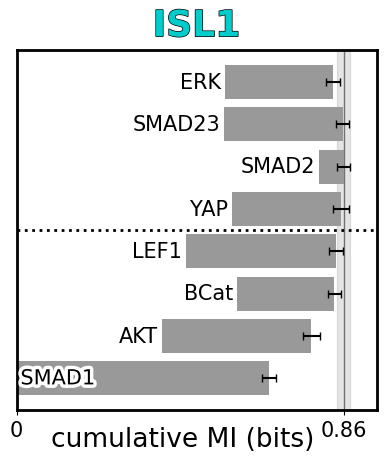

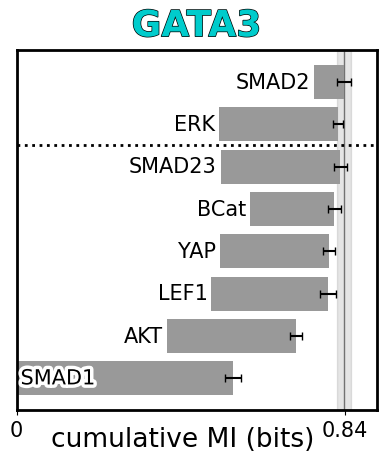

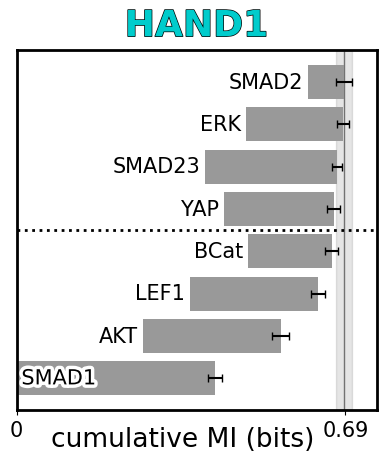

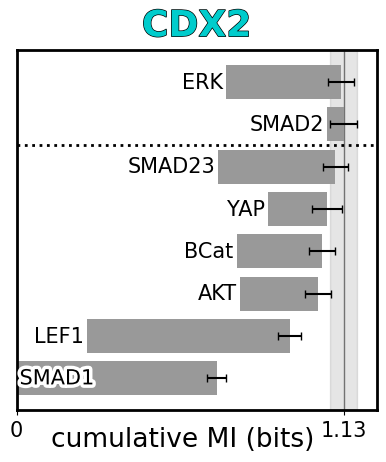

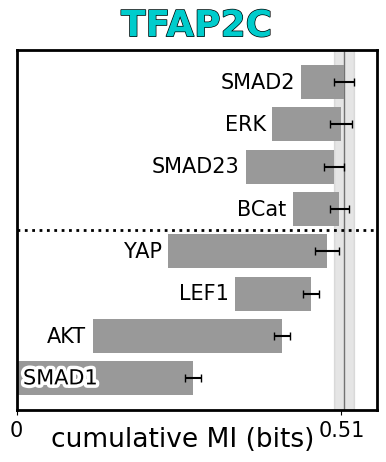

...

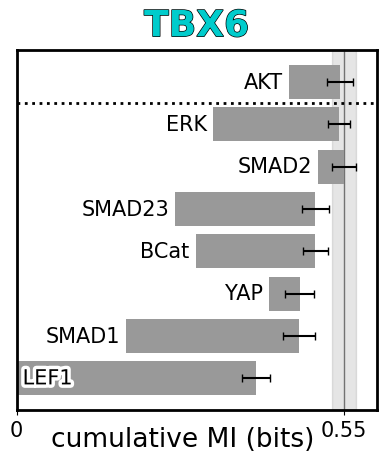

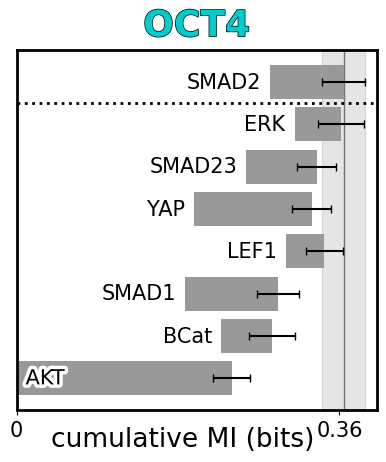

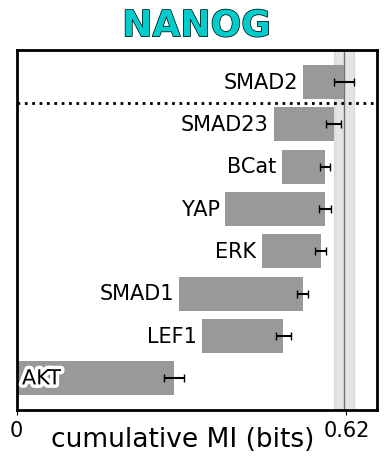

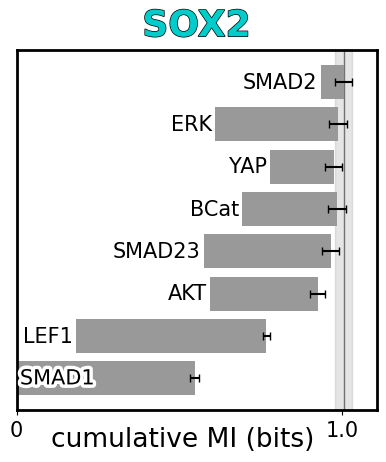

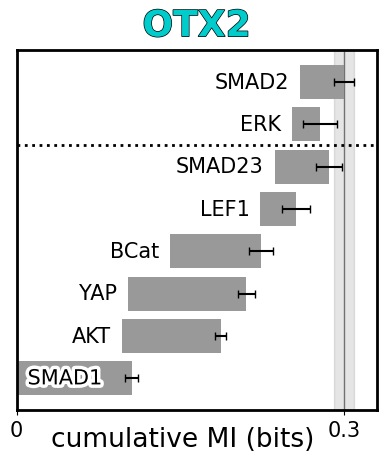

In [24]:
importlib.reload(IIF);
N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
mygenes = gene_names
signals = signal_names

IIF.plotCumulativeMI(data, cond, dataDir, mygenes, signals, signal_names_simplified, N_run, hyperparam, checkoverfit=False)

==========ISL1====================
rd: 1
250509_Exp20/251115_VIB_1D_B50_pSMAD1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncYAP_avg.csv
250509_Exp20/251115_VIB_1D_B50_BCat_avg.csv
250509_Exp20/251115_VIB_1D_B50_LEF1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD2_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD23_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopERK_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.66(0.04)
selected best: ('pSMAD1',), 0.66(0.04)
rd: 2
250509_Exp20/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_BCat_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_LEF1_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD2_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD23_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopERK_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopAKT_pSMAD1_avg.csv
best mean: ('pSMAD1', 'cytopERK'), 0.78(0.05)
selected best: ('pSMAD1', 'cytopERK'), 0.78(0.05)
rd: 3
250509_Exp20/251115_VIB_3D_B50_cyt

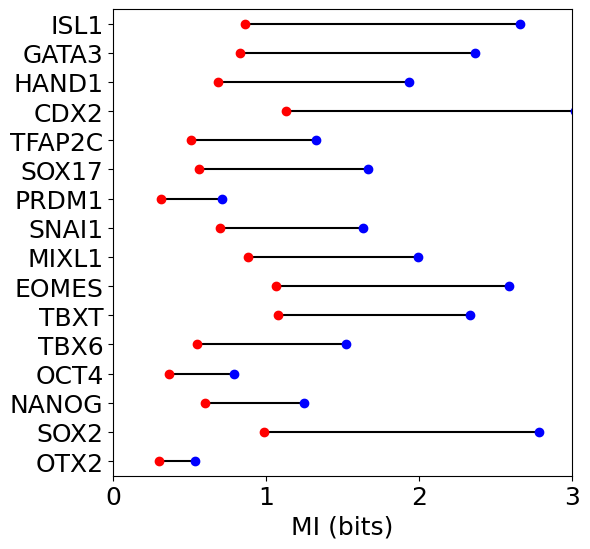

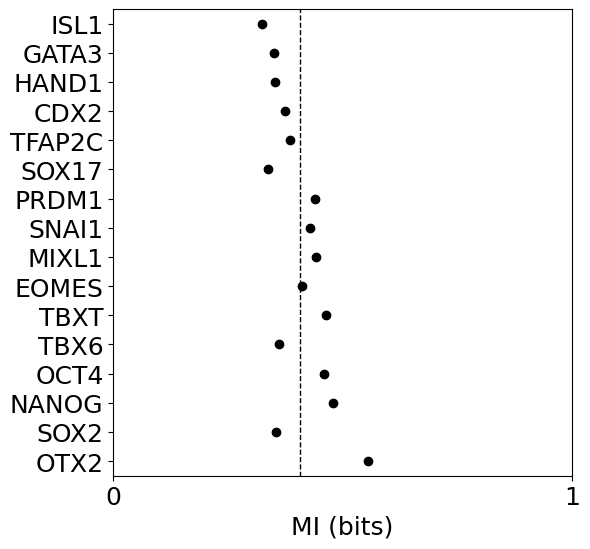

In [25]:
# FOR SI FIGURE
N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
mygenes = gene_names
signals = signal_names

MI_dec = IIF.plotRedundantMI(dataDir, data, cond, mygenes, signals, N_run, hyperparam)

### Visualization of signals and fate

In [236]:
# CONVERT DATA INTO EXPERIMENT AND COLONY OBJECTS
col = dict();
for colID in np.unique(data['Colony']):
    col[colID] = IIF.Colony(data[data['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350);
    col[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col[colID].calcPosError(sigma=1)

exp = IIF.MPexperiment(col, meta);
exp.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


In [243]:
percentiles = {'pSMAD1': [50, 99],
 'YAP': [10, 99.9],
 'BCat': [1, 99],
 'LEF1': [1, 99],
 'SMAD23': [1, 99],
 'pERK': [5, 99],
 'pAKT': [10, 99],
 'SMAD2': [1, 99],
 'ISL1': [90, 99.6],
 'GATA3': [1, 99],
 'HAND1': [1, 99],
 'CDX2': [1, 99],
 'TFAP2C': [1, 99],
 'SOX17': [1, 99],
 'PRDM1': [90, 99.5],
 'SNAI1': [1, 99],
 'MIXL1': [1, 99],
 'EOMES': [1, 99],
 'TBXT': [1, 99],
 'TBX6': [70, 99],
 'OCT4': [1, 99],
 'NANOG': [40, 99],
 'SOX2': [1, 99],
 'OTX2': [1, 99],
 'DAPI': [1, 99]}

loading 250509_Exp20\230112_6i9rd_exp20_RD3_ISL1_TBXT_pSMAD1\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230113_6i9rd_exp20_RD4_EOMES_YAP_FOXA2bad\MIP\stitched_MIP_p0000_w0002_t0000.jpg
loading 250509_Exp20\230115_6i9rd_exp20_RD6_BCat_TBX6_SMAD2\MIP\stitched_MIP_p0000_w0001_t0000.jpg
loading 250509_Exp20\230111_6i9rd_exp20_RD2_GATA3_OTX2_LEF1\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230115_6i9rd_exp20_RD6_BCat_TBX6_SMAD2\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230110_6i9rd_exp20_RD1_SMAD23_pAKT_SOX17\MIP\stitched_MIP_p0000_w0001_t0000.jpg
loading 250509_Exp20\230120_6i9rd_exp20_RD10_FOXA2m_pERK_FOXA2\MIP\stitched_MIP_p0000_w0002_t0000.jpg
loading 250509_Exp20\230110_6i9rd_exp20_RD1_SMAD23_pAKT_SOX17\MIP\stitched_MIP_p0000_w0002_t0000.jpg
loading overlay 250509_Exp20\230112_6i9rd_exp20_RD3_ISL1_TBXT_pSMAD1\MIP\stitched_MIP_p0000_w0001_t0000.jpg


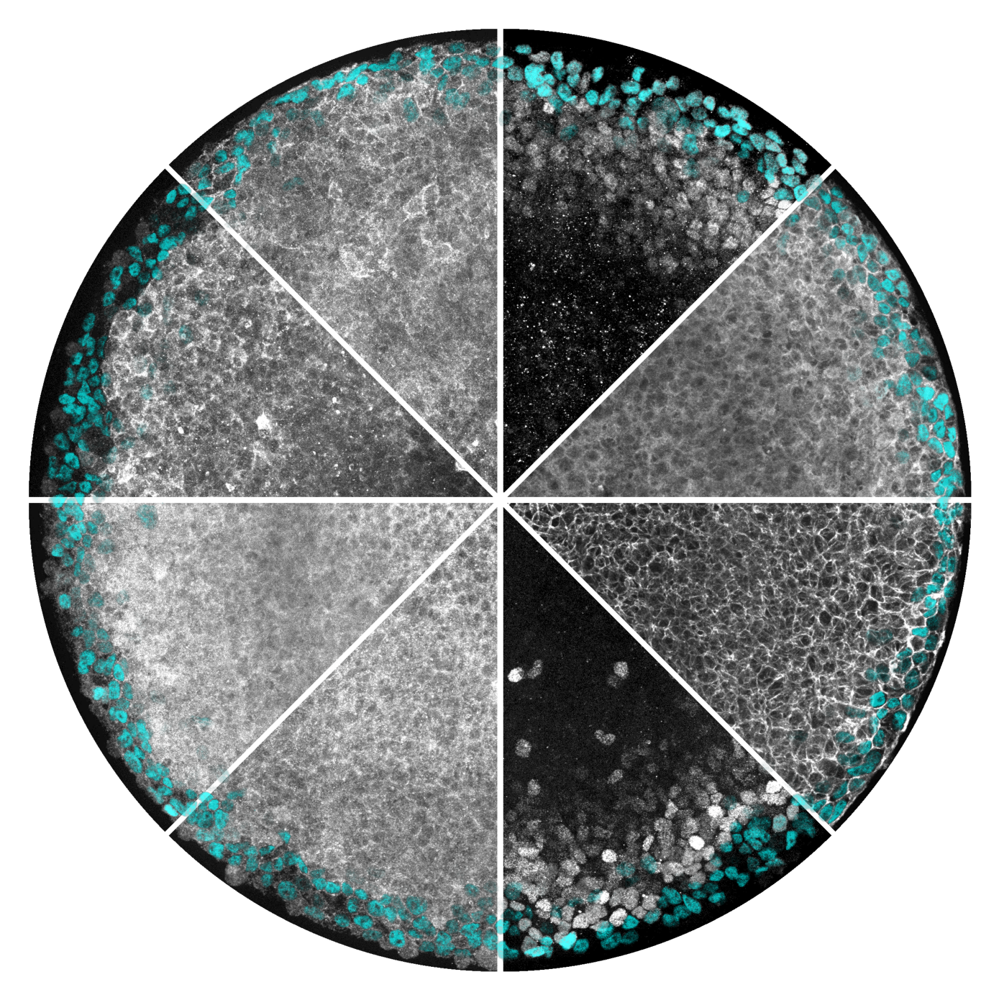

In [257]:
# example channel overlay

colID = 1
stains = signal_names_images
#stains = ['NANOG']


RGBbase, image_meta = IIF.makeRGBbase(
    col, colID, stains, dataDir,
    crop_margin=30, center_x_margin=-20, center_y_margin=10,
    Ilim=None, percentiles=percentiles,
    pie_sectors=True, grayscale_background=True, rdStr='RD'
)


overlay_markers = ['ISL1']
for ov in overlay_markers:
    RGBoverlay = IIF.applyOverlay(RGBbase, image_meta, overlay_marker=ov, overlay_alpha=0.7)

    fig, ax = plt.subplots(1, 1, figsize=(14, 14))
    ax.imshow(RGBoverlay)
    ax.axis('off')
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()
    imageio.imwrite(f'Fig3/eight_way_pie_plot_plus_{ov}_cyan.png', RGBoverlay)
    plt.show()

### Exp 28 comparison

In [26]:
# LOAD DATA 

dataDir28 = '250722_Exp28'
data28 = pd.read_csv(dataDir28 + '/exp28_data_bgsub_scaled_251211.csv') 
data28.rename(columns={'SOX17_1': 'SOX17'}, inplace=True)
data28.rename(columns={'DAPI_1': 'DAPI'}, inplace=True)

# remove a few rows of bad data if necessary, reindex
mask = data28[signal_names + gene_names].isna() | (data28[signal_names + gene_names] < 0)
mask = mask.any(axis=1)
print(np.sum(mask))
data28 = data28[~mask]
data28.index = range(0, len(data28))

thresh28 = {'ISL1': 500, 'GATA3': 500, 'HAND1': 500, 'CDX2': 300, 'TFAP2C': 600,'SOX17': 300, 'PRDM1': 650, 'NANOG': 1000, 'TBX6': 600,'TBXT': 250, 'MIXL1': 400, 'EOMES': 200, 'SNAI1': 200,'OCT4': 500, 'SOX2': 200, 'OTX2': 400}

1


In [60]:
signal_combinations = {}
signal_combinations[1] = [['pSMAD1','ncYAP','BCat','LEF1','ncSMAD2','ncSMAD23','cytopERK','cytopAKT'],
                          ['pSMAD1','ncYAP','BCat','LEF1','ncSMAD2','ncSMAD23','cytopERK'],
                          ['pSMAD1', 'ncYAP', 'BCat', 'LEF1', 'ncSMAD23', 'cytopERK']
                          ]
legend_str = {}
legend_str[1] = ['all signals','-pAKT','-pAKT-SMAD2']

seti=1
pred_subs = IIF.getPreds2(data, dataDir, signal_combinations[seti], gene_names, hyperparam)
pred_subs28 = IIF.getPreds2(data28, dataDir28, signal_combinations[seti], gene_names, hyperparam)

ERROR! Session/line number was not unique in database. History logging moved to new session 1128
calculating: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv
  Run 0/3
Elapsed time: 58.040990114212036 seconds
  Run 1/3
Elapsed time: 58.31735849380493 seconds
  Run 2/3
Elapsed time: 56.87638306617737 seconds
Elapsed time: 46.231853723526 seconds
calculating: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv
  Run 0/3
Elapsed time: 58.49622559547424 seconds
  Run 1/3
Elapsed time: 59.38351917266846 seconds
  Run 2/3
Elapsed time: 59.14589834213257 seconds
Elapsed time: 45.17082977294922 seconds
calculating: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv
  Run 0/3
Elapsed time: 58.43418884277344 seconds
  Run 1/3
Elapsed time: 56.62931847572327 seconds
  Run 2/3
Elapsed time: 56.98750162124634 seconds
Elapsed time: 45.1090612411499 seconds
calcula

In [62]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs, thresh, gene_names)
performances28, _ = IIF.calcPerformance(data28, pred_subs28, thresh28, gene_names)

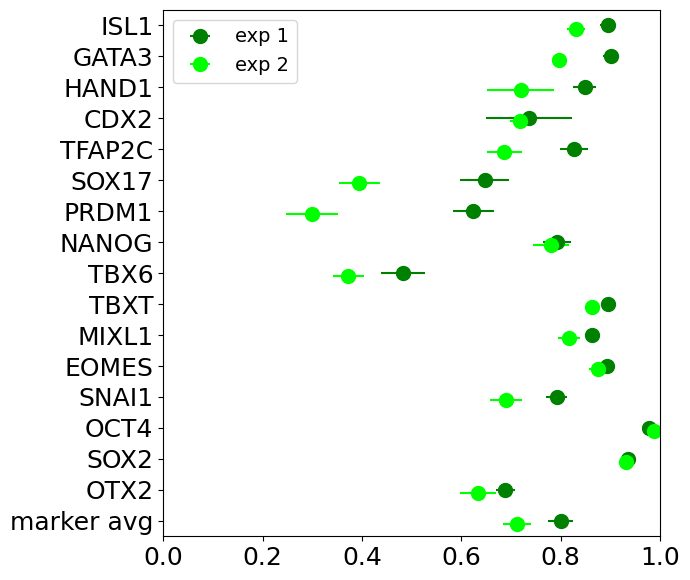

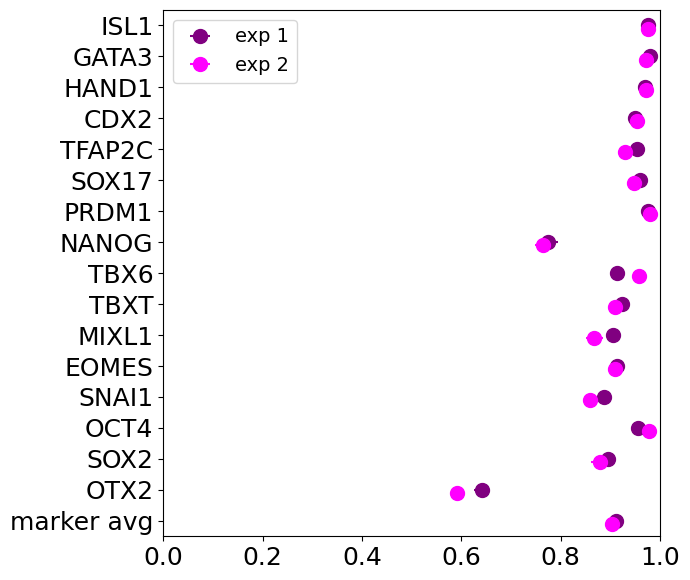

In [63]:
# plot f1 and accuracy per gene for exp 20 vs 28

cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'marker': labels}
xlim = 1

legend_str = ['exp 1','exp 2']

n_colors = 2

for prefix, labels in labeldict.items():
    
    for score in ['f1','acc']:

        if score == 'f1':
            colors = [(0, 1/2, 0, 1), (0, 1, 0, 1)]
        elif score == 'acc':
            colors = [(1/2, 0, 1/2, 1), (1, 0, 1, 1)]
            
        fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
        fs = 18
        ms = 10

        k = 'BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1'
        ct = 1
        c = colors[ct-1]
        offset = (ct-1)*0.1
            
        means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
        stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
        ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)

        ct = 2
        c = colors[ct-1]
        offset = (ct-1)*0.1
            
        means = performances28[cond].loc[labels, str(k)+'-'+score+'-avg']
        stds = performances28[cond].loc[labels, str(k)+'-'+score+'-std']
        ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
        
        labels_tick = labels.copy()
        labels_tick[-1] = prefix + ' avg'
        ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
        ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
        ax.tick_params(axis='both', labelsize=fs)
        
        ax.set_ylim([-0.5, len(labels) -0.5])
        ax.set_xlim([0, xlim])
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.legend(legend_str, fontsize=14)
        plt.savefig('FigS3/'+prefix+score+'_VIB32-2-2_exp20v28.png') 

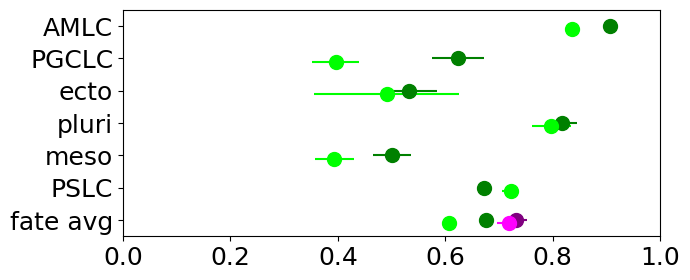

In [64]:
# plot fate f1 and accuracy for exp28 vs exp20

cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'fate': otherlabels}



for prefix, labels in labeldict.items():

    fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
    fs = 18
    ms = 10
    k = 'BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1'
    
    for score in ['f1','acc']:

        if score == 'f1':
            colors = [(0, 1/2, 0, 1), (0, 1, 0, 1)]
        elif score == 'acc':
            colors = [(1/2, 0, 1/2, 1), (1, 0, 1, 1)]
            
        ct = 1
        c = colors[ct-1]
        offset = (ct-1)*0.1
            
        means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
        stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
        ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
    
        ct = 2
        c = colors[ct-1]
        offset = (ct-1)*0.1
            
        means = performances28[cond].loc[labels, str(k)+'-'+score+'-avg']
        stds = performances28[cond].loc[labels, str(k)+'-'+score+'-std']
        ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
            
    labels_tick = labels.copy()
    labels_tick[-1] = prefix + ' avg'
    ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
    ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
    ax.tick_params(axis='both', labelsize=fs)
    
    ax.set_ylim([-0.5, len(labels) -0.5])
    ax.set_xlim([0, xlim])
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('FigS3/'+prefix+score+'_VIB32-2-2_exp28v20.png') 

## Reducing the number of signals

#### pSMAD1 only

In [67]:
signal_combinations = {}
signal_combinations[1] = [['pSMAD1'],
                       ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK','cytopAKT']
                      ]
legend_str = {}
legend_str[1] = ['pSMAD1','all signals']

pred_subs = {}
data_cond = data[data['condition']=='B50']
N_run=3

pred_subs = IIF.getPreds2(data, dataDir, signal_combinations[1], gene_names, hyperparam)

# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs, thresh, gene_names)

calculating: 250509_Exp20/Fig3_VIB/Fig3_VIB_pSMAD1_B50predonly.csv
  Run 0/3
Elapsed time: 57.57715463638306 seconds
  Run 1/3
Elapsed time: 60.80935716629028 seconds
  Run 2/3
Elapsed time: 62.203720569610596 seconds
Elapsed time: 51.699678897857666 seconds
loading: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv


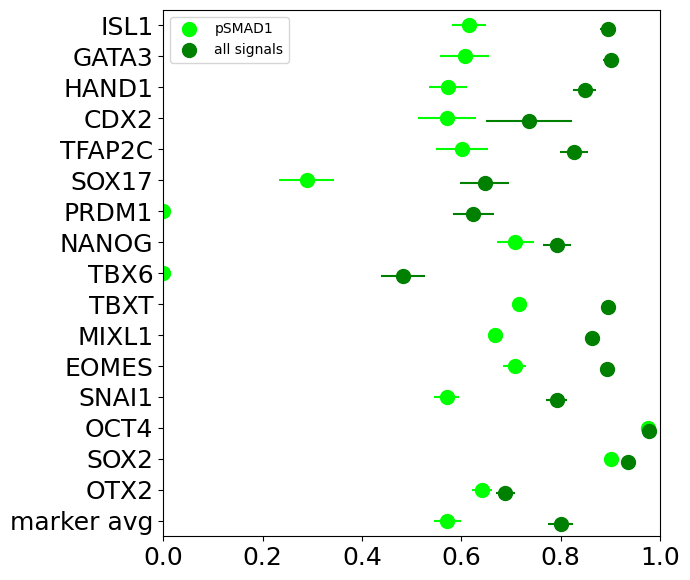

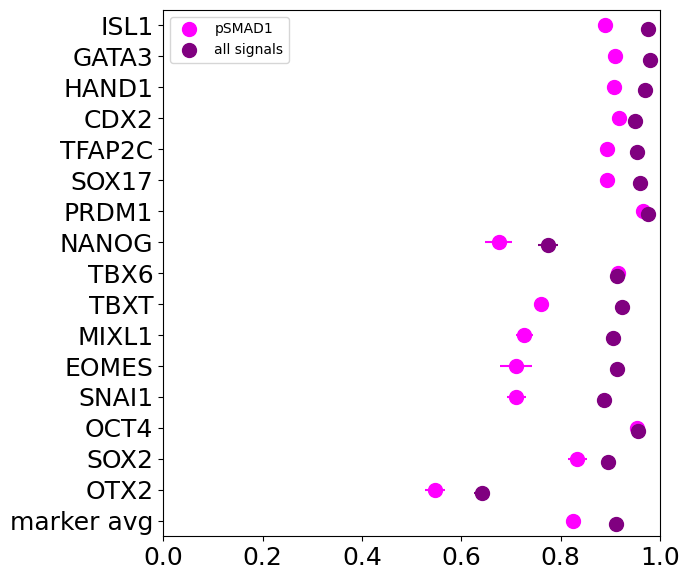

In [68]:
# plot f1 and accuracy per gene 

cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'marker': labels}
xlim = 1

for prefix, labels in labeldict.items():
    
    for score in ['f1','acc']:

        if score=='f1':
            colors = [(0,1,0),(0,1/2,0)]
        else:
            colors = [(1,0,1),(1/2,0,1/2)]
        
        fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
        fs = 18
        ms = 10

        for ct, k in enumerate(pred_subs.keys(), start=1):
            
            c = colors[ct-1]
            offset = (ct-1)*0.1
                
            means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
            stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
            ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
        
        labels_tick = labels.copy()
        labels_tick[-1] = prefix + ' avg'
        ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
        ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
        ax.tick_params(axis='both', labelsize=fs)
        
        ax.set_ylim([-0.5, len(labels) -0.5])
        ax.set_xlim([0, xlim])
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.legend(legend_str[seti], fontsize=10)
        plt.savefig('FigS5/'+prefix+score+'_VIB32-2-2_pSMAD1alone.png') 

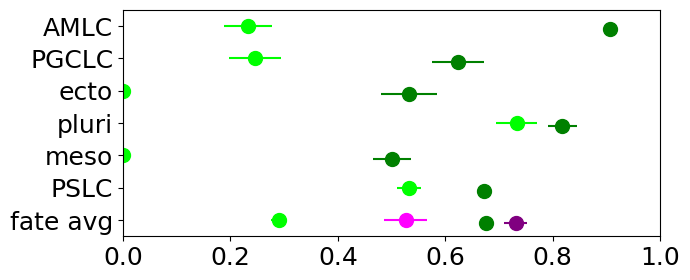

In [69]:
# plot fate f1 and accuracy for Nhid=24, Nlay=2, for different input signals
labeldict = {'fate': otherlabels}

for prefix, labels in labeldict.items():

    fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
    fs = 18
    ms = 10
    
    for score in ['f1','acc']:

        if score=='f1':
            colors = [(0,1,0),(0,1/2,0)]
        else:
            colors = [(1,0,1),(1/2,0,1/2)]

        
        for ct, k in enumerate(pred_subs.keys(), start=1):
            
            c = colors[ct-1]
            offset = (ct-1)*0.1
        
            means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
            stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
            ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
            
    labels_tick = labels.copy()
    labels_tick[-1] = prefix + ' avg'
    ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
    ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
    ax.tick_params(axis='both', labelsize=fs)
    
    ax.set_ylim([-0.5, len(labels) -0.5])
    ax.set_xlim([0, xlim])
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('FigS5/'+prefix+score+'_VIB32-2-2_pSMAD1alone.png') 

In [70]:
# CONVERT DATA INTO EXPERIMENT AND COLONY OBJECTS
col = dict();
for colID in np.unique(data['Colony']):
    col[colID] = IIF.Colony(data[data['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350);
    col[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col[colID].calcPosError(sigma=1)

exp = IIF.MPexperiment(col, meta);
exp.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


In [71]:
# convert to colony objects
col_pred = dict();
for colIDp in np.unique(data['Colony']):
    col_pred[colIDp] = IIF.Colony(pred_subs['pSMAD1']['avg'][pred_subs['pSMAD1']['avg']['Colony']==colIDp], colIDp, meta, features=feature_names, nominalRadius=350);
    col_pred[colIDp].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col_pred[colIDp].calcPosError(sigma=1)

exp_pred = IIF.MPexperiment(col_pred, meta);
exp_pred.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


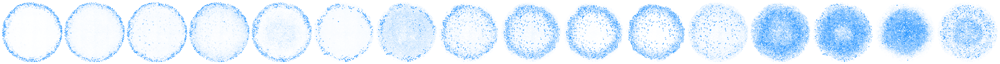

In [74]:
# GENES EXPERIMENT

colID = 1

lim = 350
m = 1
n = len(gene_names)
fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
vlim = dict()
white_blue = mcolors.LinearSegmentedColormap.from_list('white_blue', ['white','dodgerblue'])

for i,f in enumerate(gene_names):

    vlim[f] = col[colID].scatter(f, ms=ms, ax=ax[i], tol=(1,99), cmap=white_blue)
    ax[i].set_xlim([-lim,lim])
    ax[i].set_ylim([lim,-lim])

plt.savefig("FigS5/" + 'markers' + '_' + conditions[0] + file_suffix)

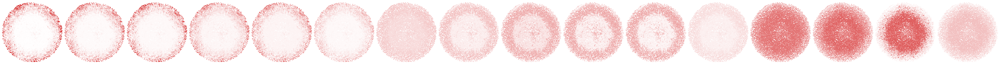

In [76]:
colID = 1
n = len(gene_names)

fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
white_red = mcolors.LinearSegmentedColormap.from_list('white_red', ['white',[0.8, 0, 0]])

for i,f in enumerate(gene_names):
    
    col_pred[colID].scatter(f, ms=ms, vmin=vlim[f][0], vmax=vlim[f][1],  ax=ax[i], cmap=white_red)
    ax[i].set_xlim([-lim,lim])
    ax[i].set_ylim([lim,-lim])

plt.savefig("FigS5/" + 'markers_predicted_pSMAD1only_' + '_' + conditions[0] + file_suffix)

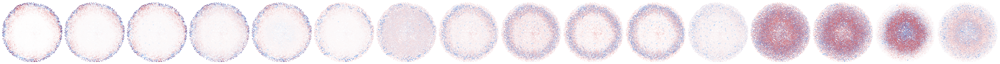

In [77]:
from matplotlib.colors import LinearSegmentedColormap

colID=1

X = (col[colID].cellData['XY']['X'] - col[colID].center[0])*col[colID].resolution
Y = (col[colID].cellData['XY']['Y'] - col[colID].center[1])*col[colID].resolution

n = len(gene_names)
fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)

for i,f in enumerate(gene_names):
    
    color = col[colID].cellData['intensities'][f]
    color_pred = col_pred[colID].cellData['intensities'][f]
    order = color.sort_values().index
    ax[i].scatter(X[order], Y[order], s=ms, c=color[order], cmap=white_blue, vmin=vlim[f][0], vmax=vlim[f][1], alpha=1, edgecolors='none')
    ax[i].scatter(X[order], Y[order], s=ms, c=color_pred[order], cmap=white_red, vmin=vlim[f][0], vmax=vlim[f][1], alpha=0.5, edgecolors='none')
    
    # idx = col[colID].cellData['intensities'][f] > thresh[f]
    # ax[i].scatter(X[idx], Y[idx], s=ms, c='b', alpha=0.3)
    #idx = col_pred[colID].cellData['intensities'][f] > thresh[f]
    #ax[i].scatter(X[idx], Y[idx], s=ms, c='r', alpha=0.3)
    
    ax[i].set_aspect('equal') 
    ax[i].axis('off')
    ax[i].set_xlim([-lim,lim])
    ax[i].set_ylim([lim,-lim])

plt.savefig("FigS5/" + 'markers_overlay_pSMAD1only_' + '_' + conditions[0] + file_suffix)

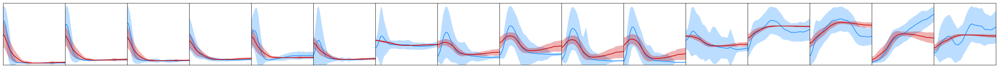

In [78]:
colID = 1
n = len(gene_names)
m = 1

fig, ax = plt.subplots(m,n, figsize=(n*2,m*2))
mode = 'cells'

for i,f in enumerate(gene_names):
    
    exp.plotRadialProfiles(f, 'B50', mode=mode, sigma=1, color='dodgerblue', ax=ax[i])
    exp_pred.plotRadialProfiles(f, 'B50', mode=mode, sigma=1, color=[0.8, 0, 0], ax=ax[i])
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].set_ylabel(None)
    ax[i].set_xlabel(None)

plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)

plt.savefig("FigS5/" + 'profile_expvpred_pSMAD1only_' + conditions[0] + '_std' + mode + file_suffix)#, bbox_inches='tight')

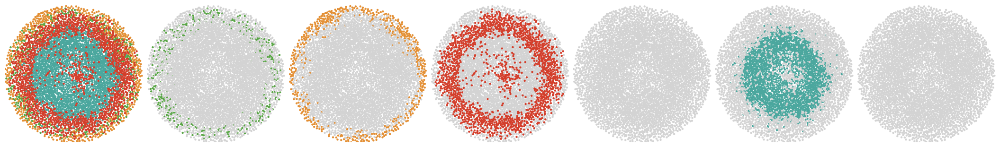

In [80]:
colID = 1
fate_names_outsidein = ['AMLC', 'PGCLC', 'PSLC', 'meso', 'pluri', 'ecto']
n = len(fate_names_outsidein) + 1

fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
ms = 10

col_pred[colID].scatter_fates(ms=ms, thresh=thresh, legend=False, ax=ax[0]) 
ax[0].set_xlim([-lim,lim])
ax[0].set_ylim ([lim,-lim])

for i,f in enumerate(fate_names_outsidein):
    fates = col_pred[colID].scatter_fates(ms=ms, thresh=thresh, legend=False, ax=ax[i+1], fate=f) 
    ax[i+1].set_xlim([-lim,lim])
    ax[i+1].set_ylim([lim,-lim])

plt.savefig("FigS5/" + 'fates_pred_pSMAD1only_scatter_' + conditions[0] + file_suffix)

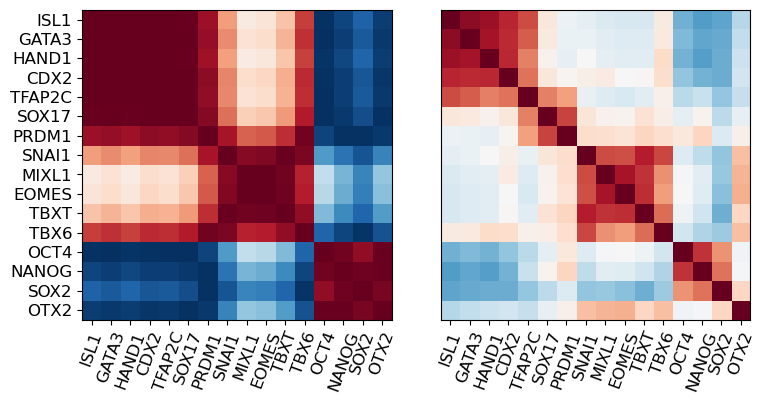

In [81]:
avg_pred = pred_subs['pSMAD1']['avg']

# correlations 
def calc_pearsoncorr(x1,x2): #only feature can be discrete
    from scipy.stats import pearsonr
    X1 = x1.to_numpy()
    X2 = x2.to_numpy()
    
    indices = (~np.isnan(X1)*~np.isnan(X2))
    
    corr = pearsonr(X1[indices].reshape(-1, 1)[:,0],X2[indices])
    return corr
    
fig_size = [8,4]  
fs2 = 12
params = {
          'figure.figsize': fig_size,
          'xtick.labelsize': fs2,
          'ytick.labelsize': fs2,
          }
plt.rcParams.update(params)

N_var = len(gene_names)

Corr_all = np.zeros((N_var,N_var,2))

for k1,g1 in enumerate(gene_names):
    for k2, g2 in enumerate(gene_names):
        Corr_all[k1,k2,0],_ = calc_pearsoncorr(data.loc[:,g1], data.loc[:,g2])
        Corr_all[k1,k2,1],_ = calc_pearsoncorr(avg_pred.loc[:,g1], avg_pred.loc[:,g2])


H,W = 1,2

plt.figure()
plt.subplot(H,W,1)
#plt.title('predicted')
plt.imshow(Corr_all[:,:,1],vmin=-1,vmax=1,cmap='RdBu_r')
#plt.colorbar()

plt.xticks(np.arange(0,N_var),labels=gene_names,rotation=70)
#plt.xticks([])
plt.yticks(np.arange(0,N_var),labels=gene_names,fontsize=fs2)


plt.subplot(H,W,2)
#plt.title('measured')
plt.imshow(Corr_all[:,:,0],vmin=-1,vmax=1,cmap='RdBu_r')
#plt.colorbar()

plt.xticks(np.arange(0,N_var),labels=gene_names,rotation=70)
#plt.yticks(np.arange(0,N_var),labels=names)
plt.yticks([])

plt.tight_layout()

plt.savefig("FigS5/" + 'g1g2_corr_matrix_VIB_pSMAD1only_' + cond + '.pdf')

#### Plot fate prediction performance for different signal combination

In [82]:
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}

signal_combinations = {}
signal_combinations[1] = [['pSMAD1'],
                       ['pSMAD1','LEF1'],
                       ['pSMAD1','LEF1','cytopERK'],
                        ['pSMAD1','LEF1','cytopERK','ncYAP'],
                        ['pSMAD1','LEF1','cytopERK','ncYAP','ncSMAD2'],
                        ['pSMAD1','LEF1','cytopERK','ncYAP','ncSMAD2','ncSMAD23'],
                       ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK','cytopAKT']
                      ]
legend_str = {}
legend_str[1] = ['pSMAD1','+LEF1','+pERK','+ncYAP','+ncSMAD2','+ncSMAD23','all signals']

signal_combinations[2] = [['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK','cytopAKT'],
                        ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],                    
                        ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'ncSMAD2', 'cytopERK','cytopAKT'],
                          ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK'],                    
                         ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],
                          ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK'],
                          ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD2', 'cytopERK'],
                      ]
legend_str[2] = ['all signals','-pAKT','-bcat','-pAKT-SMAD2','-pAKT-bcat','---SMAD2','---SMAD23']

signal_combinations[3] = [['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK','cytopAKT'],
                        ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],
                          ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],
                          ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK'],                    
                      ]
legend_str[3] = ['all signals','-pAKT','-pAKT-βcat','-pAKT-βcat-SMAD2']

signal_combinations[4] = [['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK','cytopAKT'],
                        ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],
                          ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK'],                    
                      ]
legend_str[4] = ['all signals','-pAKT','-pAKT-SMAD2']

pred_subs = {}
data_cond = data[data['condition']=='B50']
N_run=3

pred_subs = IIF.getPreds2(data, dataDir, signal_combinations[4], gene_names, hyperparam)

loading: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv
loading: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv
loading: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv


In [84]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs, thresh, gene_names)

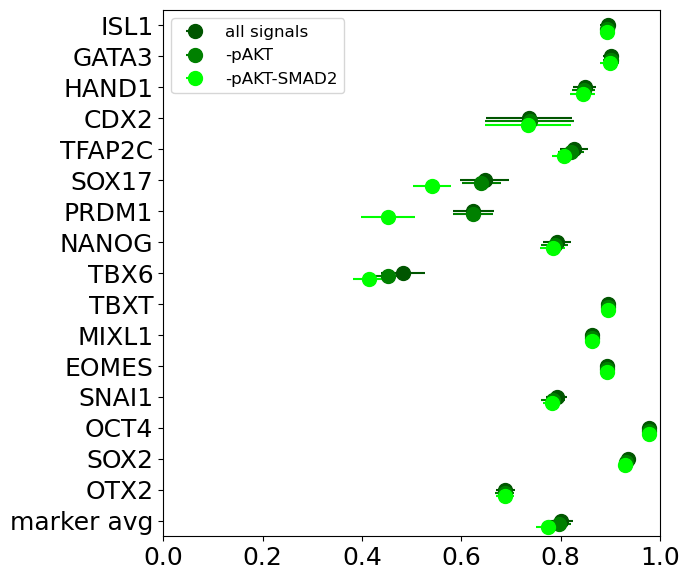

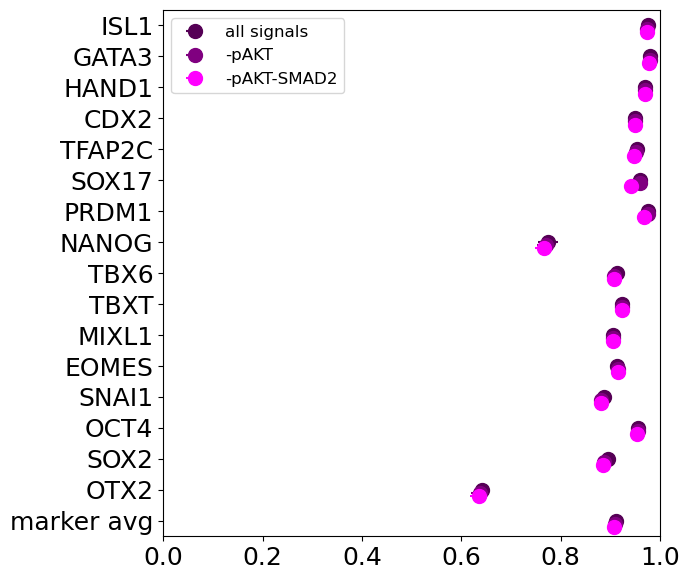

In [85]:
# plot f1 and accuracy per gene 

seti=4

cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'marker': labels}
xlim = 1

n_colors = len(pred_subs.keys())
cmap = plt.get_cmap('tab10', n_colors)
colors = [cmap(i) for i in range(n_colors)]

for prefix, labels in labeldict.items():
    
    for score in ['f1','acc']:

        if score == 'f1':
            colors = [(0, 1/3, 0, 1), (0, 1/2, 0, 1), (0, 1, 0, 1)]
        elif score == 'acc':
            colors = [(1/3, 0, 1/3, 1), (1/2, 0, 1/2, 1), (1, 0, 1, 1)]
            
        fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
        fs = 18
        ms = 10

        for ct, k in enumerate(pred_subs.keys(), start=1):
            
            c = colors[ct-1]
            offset = (ct-1)*0.1
                
            means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
            stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
            ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
        
        labels_tick = labels.copy()
        labels_tick[-1] = prefix + ' avg'
        ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
        ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
        ax.tick_params(axis='both', labelsize=fs)
        
        ax.set_ylim([-0.5, len(labels) -0.5])
        ax.set_xlim([0, xlim])
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.legend(legend_str[seti], fontsize=12)
        plt.savefig('FigS4/'+prefix+score+'_VIB32-2-2_' + str(seti) + '.png') 

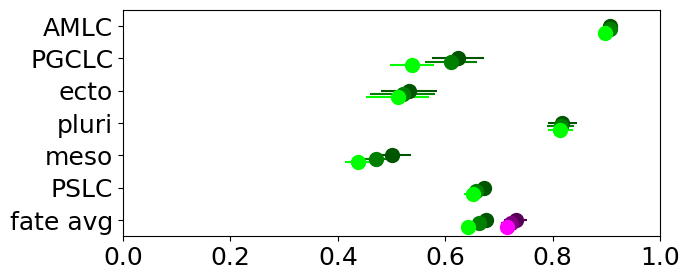

In [86]:
# plot fate f1 and accuracy for Nhid=24, Nlay=2, for different input signals

cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'fate': otherlabels}

for prefix, labels in labeldict.items():

    fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
    fs = 18
    ms = 10
    
    for score in ['f1','acc']:

        if score == 'f1':
            #colors = [(0, 1/4, 0, 1), (0, 1/3, 0, 1), (0, 1/2, 0, 1), (0, 1, 0, 1)]
            colors = [(0, 1/3, 0, 1), (0, 1/2, 0, 1), (0, 1, 0, 1)]
        elif score == 'acc':
            #colors = [(1/4, 0, 1/4, 1),(1/3, 0, 1/3, 1), (1/2, 0, 1/2, 1), (1, 0, 1, 1)]
            colors = [(1/3, 0, 1/3, 1), (1/2, 0, 1/2, 1), (1, 0, 1, 1)]
              
        for ct, k in enumerate(pred_subs.keys(), start=1):
            
            c = colors[ct-1]
            offset = (ct-1)*0.1
        
            means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
            stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
            ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
            
    labels_tick = labels.copy()
    labels_tick[-1] = prefix + ' avg'
    ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
    ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
    ax.tick_params(axis='both', labelsize=fs)
    
    ax.set_ylim([-0.5, len(labels) -0.5])
    ax.set_xlim([0, xlim])
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('FigS4/'+prefix+score+'_VIB32-2-2_' + str(seti) + '.png') 

==========ISL1====================
rd: 1
250509_Exp20/251115_VIB_1D_B50_pSMAD1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncYAP_avg.csv
250509_Exp20/251115_VIB_1D_B50_LEF1_avg.csv
250509_Exp20/251115_VIB_1D_B50_BCat_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD23_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopERK_avg.csv
best mean: ('pSMAD1',), 0.66(0.04)
selected best: ('pSMAD1',), 0.66(0.04)
rd: 2
250509_Exp20/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_LEF1_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_BCat_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD23_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopERK_pSMAD1_avg.csv
best mean: ('pSMAD1', 'cytopERK'), 0.78(0.05)
selected best: ('pSMAD1', 'cytopERK'), 0.78(0.05)
rd: 3
250509_Exp20/251115_VIB_3D_B50_cytopERK_ncYAP_pSMAD1_avg.csv
250509_Exp20/251115_VIB_3D_B50_cytopERK_LEF1_pSMAD1_avg.csv
250509_Exp20/251115_VIB_3D_B50_BCat_cytopERK_pSMAD1_avg.csv
250509_Exp20/251115_VIB_3D_B50_cytopERK_ncSMAD23_pSMAD1_a

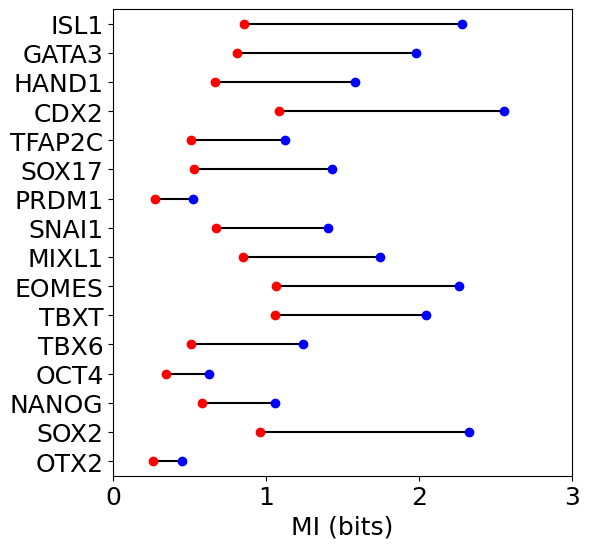

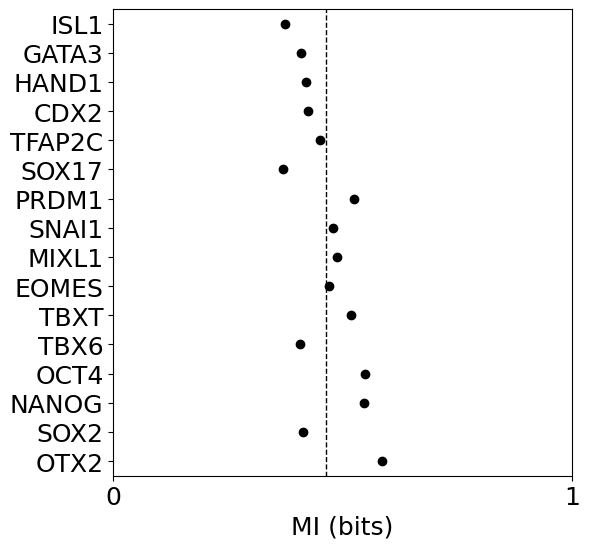

In [87]:
# FOR SI FIGURE

N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
mygenes = gene_names
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK']

MI_dec = IIF.plotRedundantMI(dataDir, data, cond, mygenes, signals, N_run, hyperparam)

## Latent space analysis

### sig2fate vs signal autoencoder

In [88]:
# ============================================================
# TRAIN SIGNAL-TO-FATE (VIB) AND SIGNAL-TO-SIGNAL (AE) MODELS
# across Ldim = 1-8, with Nlay=2, Nhid=32
# ============================================================

import importlib
importlib.reload(IIF)

N_run = 3
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK'] # 6D model
feat_names = signals
Nlay = 2
Nhid = 32
Ldim_range = range(1, len(signals)+1)

cond = 'B50'
data_cond = data[data['condition'] == cond]
colony_idx = np.unique(data_cond['Colony'])

for Ldim in Ldim_range:
    
    hyperparam = {'HIDDEN_DIM': Nhid, 'N_LAYERS': Nlay, 'LATENT_DIM': Ldim}

    for it in range(N_run):
        print(f"  Ldim={Ldim}, Run {it}/{N_run}")
        start = time.time()

        print('sig2fate')
        # --- SIGNAL-TO-FATE (already written, reuse same filenames as before) ---
        pred_df = data.copy()

        for test_colony in colony_idx:
            train_colonies = np.setdiff1d(colony_idx, test_colony)
            data_test  = data_cond[data_cond['Colony'].isin([test_colony])]
            data_train = data_cond[data_cond['Colony'].isin(train_colonies)]

            vib = IIF.VIB(data_train[feat_names], data_train[gene_names], hyperparam)
            _ = vib.train(verbose=False)
            tar_predict = vib.predict(data_test[feat_names])
            pred_df.loc[tar_predict.index, tar_predict.columns] = tar_predict

        pred_df.to_csv(
            dataDir + f'/260309_VIB_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv'
        )

        print('sig2sig')
        # --- SIGNAL-TO-SIGNAL AUTOENCODER ---
        ae_pred_df = data.copy()

        for test_colony in colony_idx:
            train_colonies = np.setdiff1d(colony_idx, test_colony)
            data_test  = data_cond[data_cond['Colony'].isin([test_colony])]
            data_train = data_cond[data_cond['Colony'].isin(train_colonies)]

            # input == output: autoencoder
            vib_ae = IIF.VIB(data_train[feat_names], data_train[feat_names], hyperparam)
            _ = vib_ae.train(verbose=False)
            sig_predict = vib_ae.predict(data_test[feat_names])
            ae_pred_df.loc[sig_predict.index, sig_predict.columns] = sig_predict

        ae_pred_df.to_csv(
            dataDir + f'/260309_AE_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv'
        )

        end = time.time()
        print(f"  Elapsed: {end - start:.1f}s")

  Ldim=1, Run 0/3
sig2fate
sig2sig
  Elapsed: 115.8s
  Ldim=1, Run 1/3
sig2fate
sig2sig
  Elapsed: 115.8s
  Ldim=1, Run 2/3
sig2fate
sig2sig
  Elapsed: 115.1s
  Ldim=2, Run 0/3
sig2fate
sig2sig
  Elapsed: 124.1s
  Ldim=2, Run 1/3
sig2fate
sig2sig
  Elapsed: 125.2s
  Ldim=2, Run 2/3
sig2fate
sig2sig
  Elapsed: 124.0s
  Ldim=3, Run 0/3
sig2fate
sig2sig
  Elapsed: 129.9s
  Ldim=3, Run 1/3
sig2fate
sig2sig
  Elapsed: 128.0s
  Ldim=3, Run 2/3
sig2fate
sig2sig
  Elapsed: 127.6s
  Ldim=4, Run 0/3
sig2fate
sig2sig
  Elapsed: 130.7s
  Ldim=4, Run 1/3
sig2fate
sig2sig
  Elapsed: 131.8s
  Ldim=4, Run 2/3
sig2fate
sig2sig
  Elapsed: 131.0s
  Ldim=5, Run 0/3
sig2fate
sig2sig
  Elapsed: 137.0s
  Ldim=5, Run 1/3
sig2fate
sig2sig
  Elapsed: 137.1s
  Ldim=5, Run 2/3
sig2fate
sig2sig
  Elapsed: 135.1s
  Ldim=6, Run 0/3
sig2fate
sig2sig
  Elapsed: 137.7s
  Ldim=6, Run 1/3
sig2fate
sig2sig
  Elapsed: 144.3s
  Ldim=6, Run 2/3
sig2fate
sig2sig
  Elapsed: 155.4s


In [89]:
# ============================================================
# LOAD, AVERAGE RUNS, COMPUTE MSE, PLOT
# ============================================================

Nlay = 2
Nhid = 32
N_run = 3
feat_names = signals
Ldim_range = range(1, len(signals)+1)

cond = 'B50'
condidx = data['condition'] == cond

# z-score ground truth once
data_cond_z_genes   = data[condidx][gene_names].apply(sp.stats.zscore, axis=0)
data_cond_z_signals = data[condidx][feat_names].apply(sp.stats.zscore, axis=0)

mse_vib_runs = {Ldim: [] for Ldim in Ldim_range}   # signal-to-fate
mse_ae_runs  = {Ldim: [] for Ldim in Ldim_range}   # signal-to-signal AE

for Ldim in Ldim_range:
    for it in range(N_run):

        # --- VIB (signal -> fate) ---
        pred_vib = pd.read_csv(
            dataDir + f'/260309_VIB_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv',
            index_col=0
        )
        pred_vib_z = pred_vib[condidx][gene_names].apply(sp.stats.zscore, axis=0)
        mse_vib_runs[Ldim].append(((data_cond_z_genes - pred_vib_z) ** 2).mean().mean())

        # --- AE (signal -> signal) ---
        pred_ae = pd.read_csv(
            dataDir + f'/260309_AE_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv',
            index_col=0
        )
        pred_ae_z = pred_ae[condidx][feat_names].apply(sp.stats.zscore, axis=0)
        mse_ae_runs[Ldim].append(((data_cond_z_signals - pred_ae_z) ** 2).mean().mean())

# Summarize across runs
Ldims = list(Ldim_range)

vib_mean = np.array([np.mean(mse_vib_runs[L]) for L in Ldims])
vib_sem  = np.array([np.std( mse_vib_runs[L]) / np.sqrt(N_run) for L in Ldims])

ae_mean  = np.array([np.mean(mse_ae_runs[L])  for L in Ldims])
ae_sem   = np.array([np.std( mse_ae_runs[L])  / np.sqrt(N_run) for L in Ldims])

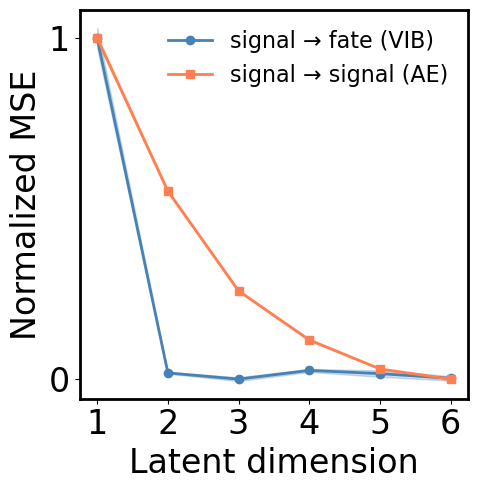

In [90]:
# ============================================================
# PLOT - scaled 0 to 1
# ============================================================

def minmax_scale(mean, sem):
    mn, mx = mean.min(), mean.max()
    mean_scaled = (mean - mn) / (mx - mn)
    sem_scaled  = sem  / (mx - mn)  # sem scales by same factor
    return mean_scaled, sem_scaled

vib_norm, vib_sem_norm = minmax_scale(vib_mean, vib_sem)
ae_norm,  ae_sem_norm  = minmax_scale(ae_mean,  ae_sem)

fs = 24
fs2 = 16
sw = 2
fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(Ldims, vib_norm, 'o-', color='steelblue', label='signal → fate (VIB)',  linewidth=2, markersize=6)
ax.fill_between(Ldims, vib_norm - vib_sem_norm, vib_norm + vib_sem_norm, alpha=0.25, color='steelblue')

ax.plot(Ldims, ae_norm,  's-', color='coral',     label='signal → signal (AE)', linewidth=2, markersize=6)
ax.fill_between(Ldims, ae_norm - ae_sem_norm, ae_norm + ae_sem_norm, alpha=0.25, color='coral')

ax.set_xlabel('Latent dimension', fontsize=fs)
ax.set_ylabel('Normalized MSE', fontsize=fs)
ax.set_xticks(Ldims)
ax.set_yticks([0, 1])
ax.tick_params(labelsize=fs)
ax.legend(fontsize=fs2, frameon=False)
ax.set_box_aspect(1)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout()
plt.savefig(f'FigS7/VIB_{len(signals)}D_vs_AE_MSE_vs_Ldim_Nhid{Nhid}_Nlay{Nlay}_scaled01.png', dpi=150)
plt.show()

### Initial latent space analysis: fate map

In [11]:
# TRAIN THE MODEL ON ALL B50 DATA TO LOOK AT LATENT SPACE;

N_run = 20
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK']
genes = gene_names

vib = {}

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]


for run in range(0, N_run):

    # set seeds for reproducibility
    torch.manual_seed(run)
    np.random.seed(run)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(run)

    vib[run] = IIF.VIB(feat_train, tar_train, hyperparam)
    
    if not os.path.exists(dataDir + '/modelws_' + str(run) + '_' + str(len(signals)) + 'D' + '.pth'):
        print('run VIB')
        _ = vib[run].train(verbose=False)
        torch.save(vib[run].model, dataDir + '/modelws_' + str(run) + '_' + str(len(signals)) + 'D' + '.pth')
    else:
        print('load VIB')
        filepath = dataDir + '/modelws_' + str(run) + '_' + str(len(signals)) + 'D' + '.pth';
        vib[run].model = torch.load(filepath, weights_only=False)
        print(filepath)

run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB
run VIB


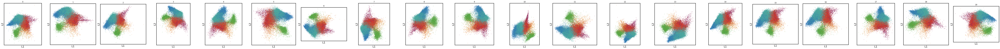

In [12]:
# CHECK REPRODUCIBILITY OF LATENT SPACE

fs=18
sw = 2
n=1
m=N_run
fig, ax = plt.subplots(n, m, figsize=(5*m, 5*n))

cond = 'B50'

for run in range(0,N_run):
    
    model = vib[run].model
    
    mask = (data['condition'] == cond)
    #mask = np.ones(len(data), dtype=bool)

    X = vib[run].scaler_X_run.transform(data.loc[mask, signals])
    X = torch.FloatTensor(X).to(device)
    
    # 2D model
    model.eval() 
    with torch.no_grad():
        mu, _ = model.encode(X)
    
    L1 = mu[:, 0].cpu().numpy()
    L2 = mu[:, 1].cpu().numpy()
    
    # Standardize target
    #scaler_y = StandardScaler()
    L1_scaled = (L1 - L1.mean())/L1.std()
    L2_scaled = (L2 - L2.mean())/L1.std()
    
    fates,_ = IIF.return_fates(data[mask],thresh=thresh)
    colors = [IIF.colmap_fates[f] for f in fates]
    
    ax[run].scatter(L1_scaled, L2_scaled,c=colors, s=1);
    #ax.scatter(L1_scaled,L2_scaled,c=[0.4,0.4,0.4], s=1);
    #ax.scatter(L1,L2,c=[0.4,0.4,0.4], s=1);
    
    ax[run].set_xlabel('L1',fontsize=fs)
    ax[run].set_ylabel('L2',fontsize=fs)
    ax[run].set_xticks([]);
    ax[run].set_yticks([]);
    ax[run].set_title(str(run))
    
    # ax.set_ylim([-0.7, 0.7])
    # ax.set_xlim([-1, 0.4]);
    
    for spine in ax[run].spines.values():
        spine.set_linewidth(sw)
    
    ax[run].set_aspect('equal', adjustable='box')
    plt.tight_layout()
    

plt.savefig(dataDir+'/LS_fate_reproducibility_' + str(len(signals)) + 'D_new.png')


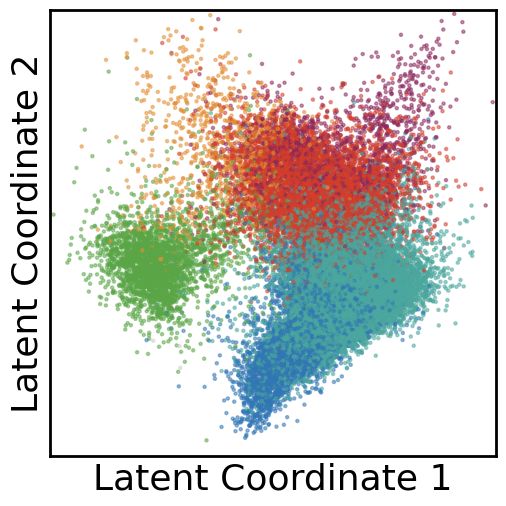

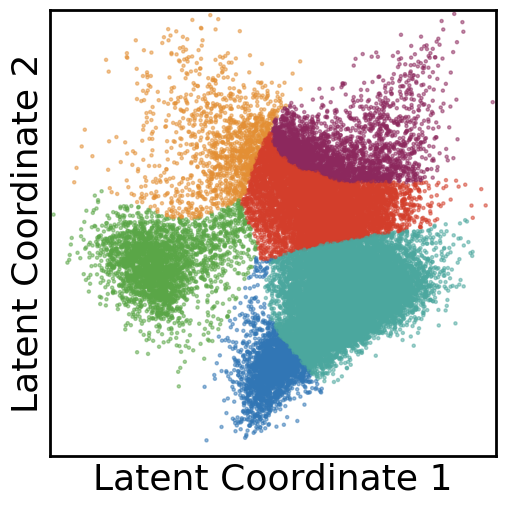

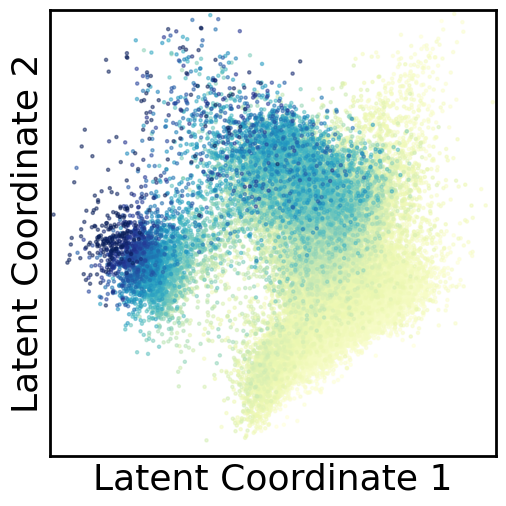

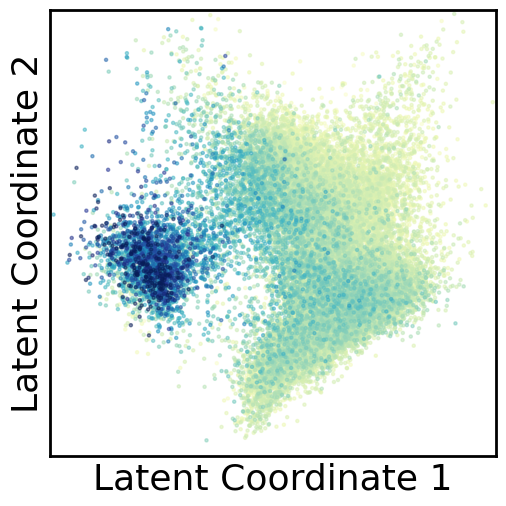

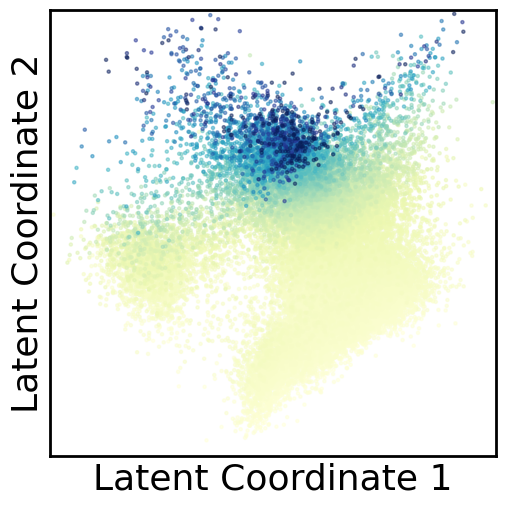

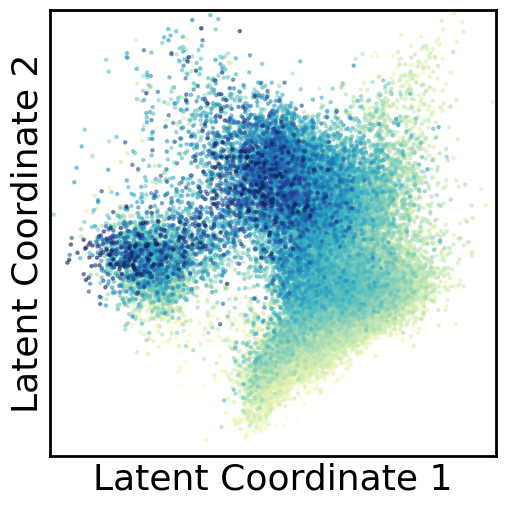

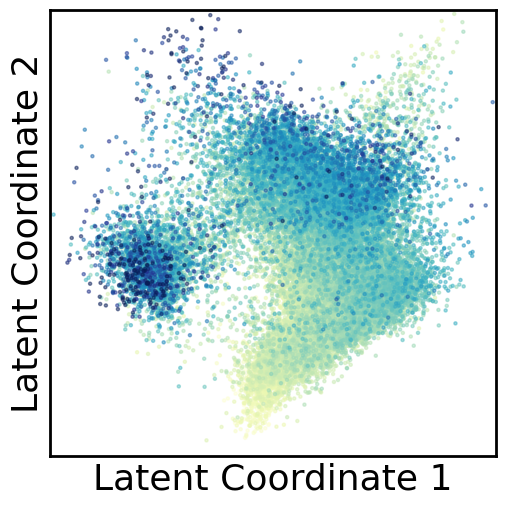

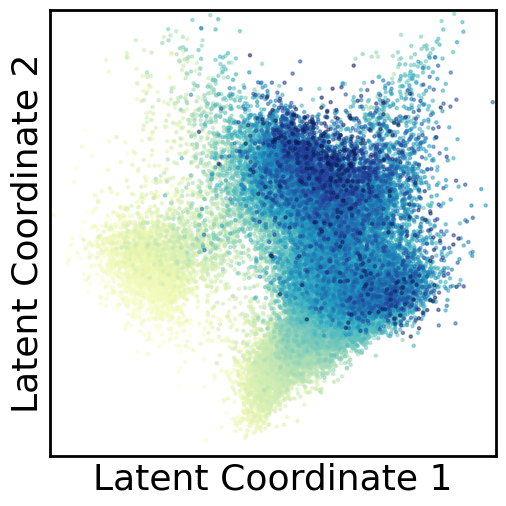

In [208]:
# VISUALIZE LATENT SPACE
N_run = 20
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK']
genes = gene_names
run = 12

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]

# Load chosen VIB model
vib_choice = IIF.VIB(feat_train, tar_train, hyperparam)
vib_choice.model = torch.load(
    os.path.join(dataDir, f'modelws_12_{len(signals)}D.pth'),
    map_location='cpu', weights_only=False
)

model = vib_choice.model
mask = (data['condition'] == cond)

X = vib_choice.scaler_X_run.transform(data.loc[mask, signals])
X = torch.FloatTensor(X).to(device)

# 2D model
model.eval() 
with torch.no_grad():
    mu, _ = model.encode(X)
    Y = model.decode(mu).cpu().numpy()
    Y = vib_choice.scaler_Y_run.inverse_transform(Y)
    Y = pd.DataFrame(Y, columns=gene_names, index=data[mask].index)

L1 = mu[:, 0].cpu().numpy()
L2 = mu[:, 1].cpu().numpy()

# Standardize target
#scaler_y = StandardScaler()
L1mean = L1.mean()
L2mean = L2.mean()
L1std = L1.std()

# scale by the same factor to maintain proportions
L1_scaled = (L1 - L1mean)/L1std
L2_scaled = (L2 - L2mean)/L1std

#=============PLOT=================

fs=26
sw = 2
n=1
m=1
s = 5
alpha = 0.5

for colorfor in ['exp','pred'] + signals:

    fig, ax = plt.subplots(n, m, figsize=(5*m, 5*n))

    if colorfor == 'exp':
        fates,_ = IIF.return_fates(data[mask],thresh=thresh)
        colors = [IIF.colmap_fates[f] for f in fates]
        ax.scatter(L1_scaled, L2_scaled,c=colors, s=s, alpha=alpha)
    elif colorfor == 'pred':
        fates_pred,_ = IIF.return_fates(Y,thresh=thresh)
        colors = [IIF.colmap_fates[f] for f in fates_pred]
        ax.scatter(L1_scaled, L2_scaled,c=colors, s=s, alpha=alpha)
    else:
        colors = data.loc[mask, colorfor]
        order = colors.sort_values().index
        tol=(0.05,99.5)
        vmin = np.percentile(colors, tol[0])
        vmax = np.percentile(colors, tol[1])
        ax.scatter(L1_scaled[order], L2_scaled[order],c=colors[order], s=s, cmap='YlGnBu',vmin=vmin,vmax=vmax, alpha=alpha)
    
    ax.set_xlabel('Latent Coordinate 1',fontsize=fs)
    ax.set_ylabel('Latent Coordinate 2',fontsize=fs)
    ax.set_xticks([]);
    ax.set_yticks([]);
    
    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    # Make plot square by extending axis limits without changing aspect ratio
    marg = 0.5
    xlim = (np.percentile(L1_scaled, 0.1) - marg, np.percentile(L1_scaled, 99.9) + marg)
    ylim = (np.percentile(L2_scaled, 0.1) - marg, np.percentile(L2_scaled, 99.9) + marg)
    
    # xlim = (L1_scaled.min(), L1_scaled.max()) #ax[run].get_xlim()
    # ylim = (L2_scaled.min(), L2_scaled.max()) #ax[run].get_ylim() 
    
    x_range = xlim[1] - xlim[0]
    y_range = ylim[1] - ylim[0]
    
    # Find the larger range
    max_range = max(x_range, y_range)
    
    # Calculate centers
    x_center = (xlim[0] + xlim[1]) / 2
    y_center = (ylim[0] + ylim[1]) / 2
    
    L1smin = x_center - max_range/2
    L1smax = x_center + max_range/2
    L2smin = y_center - max_range/2
    L2smax = y_center + max_range/2
    
    # Set new limits centered around the data with equal range
    ax.set_xlim(L1smin, L1smax)
    ax.set_ylim(L2smin, L2smax)
    
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout(pad=0.5)
    
    plt.savefig('Fig3/LS_fate_' + str(len(signals)) + 'D' + '_run' + str(run) + '_' + colorfor+'.png')

In [209]:
# EXTRAPOLATE FATE MAP

# extrapolate fate map on a grid
l1 = np.linspace(L1smin, L1smax, 200)
l2 = np.linspace(L2smin, L2smax, 200)
L1grid_scaled, L2grid_scaled = np.meshgrid(l1, l2)

# ─── Unscale grid back to raw latent space for decoding ───
L1grid_raw = L1grid_scaled * L1std + L1mean
L2grid_raw = L2grid_scaled * L1std + L2mean  # note: same std as in your scaling

mugrid = np.stack([L1grid_raw.ravel(), L2grid_raw.ravel()], axis=1)
mugrid = torch.FloatTensor(mugrid).to(device)

model.eval()
with torch.no_grad():
    Y = model.decode(mugrid).cpu().numpy()
    Y = vib_choice.scaler_Y_run.inverse_transform(Y)
    Y = pd.DataFrame(Y, columns=gene_names)

fates, _ = IIF.return_fates(Y, thresh=thresh)

99.0% of data points are inside the contours


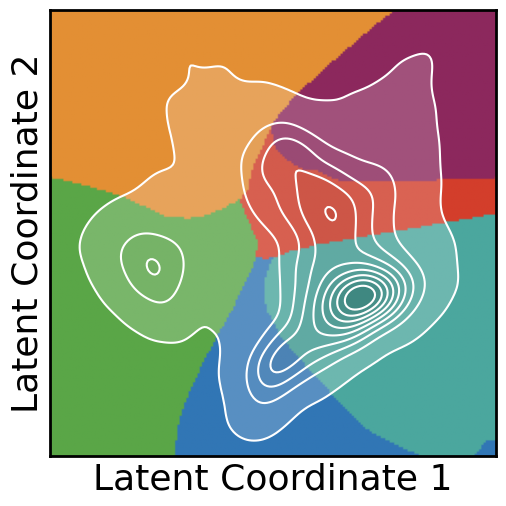

In [210]:
#--------PLOT --------------

fs=26
sw = 2
n=1
m=1
s = 5

# L1_scaled = (L1grid - L1.mean())/L1grid.std()
# L2_scaled = (L2grid - L2.mean())/L1grid.std()    
# colors = [IIF.colmap_fates[f] for f in fates]
# plt.scatter(L1_scaled, L2_scaled,c=colors, s=s)

rgb_image = np.zeros((200, 200, 3))

for i, fate in enumerate(fates):
    color = IIF.colmap_fates[fate]
    rgb = mcolors.to_rgb(color) # Convert color to RGB tuple (values between 0-1)
    rgb_image[i // 200, i % 200] = rgb

fig, ax = plt.subplots(n, m, figsize=(5*m, 5*n))
ax.imshow(rgb_image, origin='lower', extent=[L1smin, L1smax, L2smin, L2smax])

#ax.scatter(L1_scaled, L2_scaled,c='k', s=5, alpha=0.1)

# Calculate KDE for the scatter points
if len(L1_scaled) > 1:  # Need at least 2 points for KDE
    # Create KDE
    values = np.vstack([L1_scaled, L2_scaled])
    kernel = sp.stats.gaussian_kde(values)
    
    # Evaluate KDE at the actual data points
    kde_at_data = kernel(values)
    
    # Set vmin so that X% of data points are outside the contours
    data_percentile = 1  # Change this: 10 means 10% of data outside, 90% inside
    vmin = np.percentile(kde_at_data, data_percentile)
    
    # Evaluate KDE on a grid
    kde_grid = kernel(np.vstack([L1grid_scaled.ravel(), L2grid_scaled.ravel()]))
    kde_grid = kde_grid.reshape(L1grid_scaled.shape)
    
    # Define levels from vmin to max
    vmax = kde_grid.max()
    levels = np.linspace(vmin, vmax, 10)
    
    # Verify
    fraction_inside = np.sum(kde_at_data >= vmin) / len(L1_scaled)
    print(f"{fraction_inside*100:.1f}% of data points are inside the contours")
    
    ax.contourf(L1grid_scaled, L2grid_scaled, kde_grid, 
                levels=levels, cmap='Greys', alpha=0.2)
    ax.contour(L1grid_scaled, L2grid_scaled, kde_grid, 
               levels=levels, colors='white', linewidths=1.5)
    
    
ax.set_xlabel('Latent Coordinate 1',fontsize=fs)
ax.set_ylabel('Latent Coordinate 2',fontsize=fs)
ax.set_xticks([]);
ax.set_yticks([]);

for spine in ax.spines.values():
    spine.set_linewidth(sw)

ax.set_aspect('equal', adjustable='box')
plt.tight_layout(pad=0.5)

plt.savefig('Fig3/LS_fate_'  + str(len(signals))  + 'D' + '_run' + str(run)  + '_extrapolated_r.png', dpi=150, bbox_inches='tight', pad_inches=0.1)

# save fate map variables
np.save(dataDir + '/fatemap_L1grid_scaled.npy', L1grid_scaled)
np.save(dataDir + '/fatemap_L2grid_scaled.npy', L2grid_scaled)
np.save(dataDir + '/fatemap_fates.npy', np.array(fates))
np.save(dataDir + '/fatemap_limits.npy', np.array([L1smin, L1smax, L2smin, L2smax]))
np.save(dataDir + '/fatemap_L1mean_L1std.npy', np.array([L1mean, L1std]))
np.save(dataDir + '/fatemap_L2mean.npy', np.array([L2mean]))

### Establish polar coordinates on latent space

In [211]:
#=============FIND CENTER WHERE 3 SPECIFIC FATES MEET=================

import numpy as np
from scipy.stats import gaussian_kde

# ===== SPECIFY YOUR 3 FATES HERE =====
target_fates = ['ecto', 'AMLC', 'PSLC']  # CHANGE THESE TO YOUR DESIRED FATES
# ======================================

def findFateJunction(target_fates):
    
    print(f"Finding junction of: {target_fates}")
    
    # Use EXACT same grid as used to compute fates
    l1_grid = np.linspace(L1smin, L1smax, 200)
    l2_grid = np.linspace(L2smin, L2smax, 200)
    
    # Get the fate map on the grid
    fates_grid = np.array(fates).reshape(200, 200)
    
    # Check what fates are available
    unique_fates = list(set(fates))
    print(f"Available fates in grid: {unique_fates}")
    
    # Verify all target fates exist
    for fate in target_fates:
        if fate not in unique_fates:
            print(f"WARNING: {fate} not found in fate map!")
    
    # Find pixels that are adjacent to all 3 specified fates
    tri_junction_candidates = []
    
    for i in range(1, 199):
        for j in range(1, 199):
            neighborhood = fates_grid[i-1:i+2, j-1:j+2].ravel()
            neighborhood_fates = set(neighborhood)
            if all(fate in neighborhood_fates for fate in target_fates):
                tri_junction_candidates.append((i, j))
    
    print(f"Found {len(tri_junction_candidates)} tri-junction candidate pixels")
    
    if len(tri_junction_candidates) > 0:
        tri_junction_candidates = np.array(tri_junction_candidates)
        
        latent_candidates = []
        for i, j in tri_junction_candidates:
            lat1 = l1_grid[j]  # j is x (L1)
            lat2 = l2_grid[i]  # i is y (L2)
            latent_candidates.append([lat1, lat2])
        
        latent_candidates = np.array(latent_candidates)
        center_x = latent_candidates[:, 0].mean()
        center_y = latent_candidates[:, 1].mean()
        
        print(f"Tri-junction center: ({center_x:.4f}, {center_y:.4f})")
        return center_x, center_y

    else:
        print(f"No junction found for fates: {target_fates}!")
        return None, None


#=============COMPUTE POLAR COORDINATES=================

# Compute initial polar coordinates
center_x, center_y = findFateJunction(target_fates)
x_centered = L1_scaled - center_x
y_centered = L2_scaled - center_y
r = np.sqrt(x_centered**2 + y_centered**2)
theta_raw = np.arctan2(y_centered, x_centered)

#=============FIND AND FIX BRANCH CUT=================

print("Finding optimal branch cut location...")

angles_to_test = np.linspace(-np.pi, np.pi, 180)
densities = []

for angle in angles_to_test:
    angle_diff = np.abs(((theta_raw - angle + np.pi) % (2*np.pi)) - np.pi)
    points_in_wedge = np.sum(angle_diff < 0.1)
    densities.append(points_in_wedge)

densities = np.array(densities)

gap_angle = angles_to_test[np.argmin(densities)]
print(f"Gap detected at angle: {gap_angle:.3f} radians ({np.degrees(gap_angle):.1f} degrees)")

gap_angle = -2 # manually adjust based on what was found

# Rotate angles so the gap is at ±π and reverse direction
theta_corrected = -(theta_raw - gap_angle + np.pi)

# Wrap to [-π, π]
theta_corrected = np.arctan2(np.sin(theta_corrected), np.cos(theta_corrected))

print(f"Branch cut placed at ±π (gap was at {gap_angle:.3f} radians), angle reversed")

Finding junction of: ['ecto', 'AMLC', 'PSLC']
Available fates in grid: ['ecto', 'pluri', 'AMLC', 'meso', 'PSLC', 'PGCLC']
Found 4 tri-junction candidate pixels
Tri-junction center: (-0.8380, 0.0035)
Finding optimal branch cut location...
Gap detected at angle: -2.264 radians (-129.7 degrees)
Branch cut placed at ±π (gap was at -2.000 radians), angle reversed


### Fit latent coordinates as a function of input signals directly

In [214]:
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score

def pack(v1, v2):
    return np.concatenate([v1, v2])

def unpack(params):
    v1 = params[:n_signals]
    v2 = params[n_signals:]
    return v1, v2

def orthogonality_constraint(params):
    v1, v2 = unpack(params)
    return np.dot(v1, v2)

def loss_direct(params):
    w1, w2 = unpack(params)
    res1 = L1_c - X_c @ w1
    res2 = L2_c - X_c @ w2
    return np.mean(res1**2) + np.mean(res2**2)


# ============================================================
# CONSTRAINED OPTIMIZATION: find two orthogonal vectors
# in signal space that directly predict L1 and L2
# (centered, no unit norm constraint, no post-hoc rescaling)
# ============================================================

n_signals = len(signals)
mask = (data['condition'] == cond)
X_signals_z = vib_choice.scaler_X_run.transform(data.loc[mask, signals])
X_signals_z = torch.FloatTensor(X_signals_z).cpu().to(device)

model = vib_choice.model
model.eval() 
with torch.no_grad():
    mu, _ = model.encode(X_signals_z)
L1 = mu[:, 0].cpu().numpy()
L2 = mu[:, 1].cpu().numpy()

# center everything
L1_c = L1 - L1.mean()
L2_c = L2 - L2.mean()
X_signals_z_np = X_signals_z.cpu().numpy()
X_c = X_signals_z_np - X_signals_z_np.mean(axis=0)

# convert to float64 for scipy
L1_c = L1_c.astype(np.float64)
L2_c = L2_c.astype(np.float64)
X_c  = X_c.astype(np.float64)


# initialize from regression solution, orthogonalized
from sklearn.linear_model import LinearRegression
w1_init = LinearRegression().fit(X_c, L1_c).coef_
w2_init = LinearRegression().fit(X_c, L2_c).coef_

# also ensure init vectors are float64
w1_init = w1_init.astype(np.float64)
w2_init = w2_init.astype(np.float64)
v_init  = pack(w1_init, w2_init)



constraints_direct = [
    {'type': 'eq', 'fun': orthogonality_constraint},
]


# orthogonalize init to satisfy constraint at start
w2_init = w2_init - np.dot(w2_init, w1_init) / np.dot(w1_init, w1_init) * w1_init
v_init = pack(w1_init, w2_init)

# multiple restarts to avoid local minima
best_result = None
best_loss = np.inf

n_restarts = 20
for i in range(n_restarts):

    if i == 0:
        v0 = v_init  # first try: regression initialization
    else:
        # random initialization: random orthogonal vectors scaled like data
        A = np.random.randn(n_signals, 2) * np.std(w1_init)
        Q, R = np.linalg.qr(A)
        # scale columns to roughly match regression solution
        Q[:, 0] *= np.linalg.norm(w1_init)
        Q[:, 1] *= np.linalg.norm(w2_init)
        v0 = pack(Q[:, 0], Q[:, 1])

    res = minimize(loss_direct, v0, constraints=constraints_direct, method='SLSQP',
                   options={'ftol': 1e-12, 'maxiter': 10000})

    if res.fun < best_loss:
        best_loss = res.fun
        best_result = res

w1_opt, w2_opt = unpack(best_result.x)

print(f'Optimization success: {best_result.success}')
print(f'Final loss: {best_result.fun:.4f}')
print(f'Orthogonality check: w1·w2 = {np.dot(w1_opt, w2_opt):.6f}')

# predictions (add back mean of L1, L2)
L1_pred = X_c @ w1_opt + L1.mean()
L2_pred = X_c @ w2_opt + L2.mean()

r2_L1 = r2_score(L1, L1_pred)
r2_L2 = r2_score(L2, L2_pred)
print(f'R² L1: {r2_L1:.3f}')
print(f'R² L2: {r2_L2:.3f}')

# normalize for plotting (unit vectors for interpretation)
w1_norm = w1_opt / np.linalg.norm(w1_opt)
w2_norm = w2_opt / np.linalg.norm(w2_opt)

# projections for angle/radius
p1 = X_c @ w1_opt + L1.mean()
p2 = X_c @ w2_opt + L2.mean()

np.save(dataDir + '/w1_opt_B50only'+ str(len(signals)) + 'D_run' + str(run) + '.npy', w1_opt)
np.save(dataDir + '/w2_opt_B50only'+ str(len(signals)) + 'D_run' + str(run) + '.npy', w2_opt)

# compute and save complement basis
W = np.column_stack([w1_opt, w2_opt])
Q, _ = np.linalg.qr(W)
U, s, Vt = np.linalg.svd(Q.T)
complement_basis = Vt[2:, :].T  # shape (n_signals, n_signals-2)

print(f'Complement basis shape: {complement_basis.shape}')
print(f'Orthogonality check: {np.abs(complement_basis.T @ w1_opt).max():.8f} (should be ~0)')

np.save(dataDir + '/complement_basis_B50only'+ str(len(signals)) + 'D_run' + str(run) + '.npy', complement_basis)

Optimization success: True
Final loss: 0.3141
Orthogonality check: w1·w2 = 0.000000
R² L1: 0.846
R² L2: 0.808
Complement basis shape: (6, 4)
Orthogonality check: 0.00000000 (should be ~0)


In [218]:
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score

# ============================================================
# CONSTRAINED OPTIMIZATION: find two orthogonal vectors
# in signal space that directly predict L1 and L2
# (centered, no unit norm constraint, no post-hoc rescaling)
# ============================================================

n_signals = len(signals)
mask = (data['condition'] == cond)
X_signals_z = vib_choice.scaler_X_run.transform(data.loc[mask, signals])

# center everything
L1_c = L1 - L1.mean()
L2_c = L2 - L2.mean()
X_c  = X_signals_z - X_signals_z.mean(axis=0)

def pack(v1, v2):
    return np.concatenate([v1, v2])

def unpack(params):
    v1 = params[:n_signals]
    v2 = params[n_signals:]
    return v1, v2

def orthogonality_constraint(params):
    v1, v2 = unpack(params)
    return np.dot(v1, v2)

def loss_direct(params):
    w1, w2 = unpack(params)
    res1 = L1_c - X_c @ w1
    res2 = L2_c - X_c @ w2
    return np.mean(res1**2) + np.mean(res2**2)

constraints_direct = [
    {'type': 'eq', 'fun': orthogonality_constraint},
]

# initialize from regression solution, orthogonalized
from sklearn.linear_model import LinearRegression
w1_init = LinearRegression().fit(X_c, L1_c).coef_
w2_init = LinearRegression().fit(X_c, L2_c).coef_
# orthogonalize init to satisfy constraint at start
w2_init = w2_init - np.dot(w2_init, w1_init) / np.dot(w1_init, w1_init) * w1_init
v_init = pack(w1_init, w2_init)

# multiple restarts to avoid local minima
best_result = None
best_loss = np.inf

n_restarts = 20
for i in range(n_restarts):

    if i == 0:
        v0 = v_init  # first try: regression initialization
    else:
        # random initialization: random orthogonal vectors scaled like data
        A = np.random.randn(n_signals, 2) * np.std(w1_init)
        Q, R = np.linalg.qr(A)
        # scale columns to roughly match regression solution
        Q[:, 0] *= np.linalg.norm(w1_init)
        Q[:, 1] *= np.linalg.norm(w2_init)
        v0 = pack(Q[:, 0], Q[:, 1])

    res = minimize(loss_direct, v0, constraints=constraints_direct, method='SLSQP',
                   options={'ftol': 1e-12, 'maxiter': 10000})

    if res.fun < best_loss:
        best_loss = res.fun
        best_result = res

w1_opt, w2_opt = unpack(best_result.x)

print(f'Optimization success: {best_result.success}')
print(f'Final loss: {best_result.fun:.4f}')
print(f'Orthogonality check: w1·w2 = {np.dot(w1_opt, w2_opt):.6f}')

# predictions (add back mean of L1, L2)
L1_pred = X_c @ w1_opt + L1.mean()
L2_pred = X_c @ w2_opt + L2.mean()

r2_L1 = r2_score(L1, L1_pred)
r2_L2 = r2_score(L2, L2_pred)
print(f'R² L1: {r2_L1:.3f}')
print(f'R² L2: {r2_L2:.3f}')

# normalize for plotting (unit vectors for interpretation)
w1_norm = w1_opt / np.linalg.norm(w1_opt)
w2_norm = w2_opt / np.linalg.norm(w2_opt)

# projections for angle/radius
p1 = X_c @ w1_opt + L1.mean()
p2 = X_c @ w2_opt + L2.mean()

np.save(dataDir + '/w1_opt_B50only.npy', w1_opt)
np.save(dataDir + '/w2_opt_B50only.npy', w2_opt)

# compute and save complement basis
W = np.column_stack([w1_opt, w2_opt])
Q, _ = np.linalg.qr(W)
U, s, Vt = np.linalg.svd(Q.T)
complement_basis = Vt[2:, :].T  # shape (n_signals, n_signals-2)

print(f'Complement basis shape: {complement_basis.shape}')
print(f'Orthogonality check: {np.abs(complement_basis.T @ w1_opt).max():.8f} (should be ~0)')

np.save(dataDir + '/complement_basis_B50only.npy', complement_basis)

Optimization success: True
Final loss: 0.3141
Orthogonality check: w1·w2 = 0.000000
R² L1: 0.846
R² L2: 0.808
Complement basis shape: (6, 4)
Orthogonality check: 0.00000000 (should be ~0)


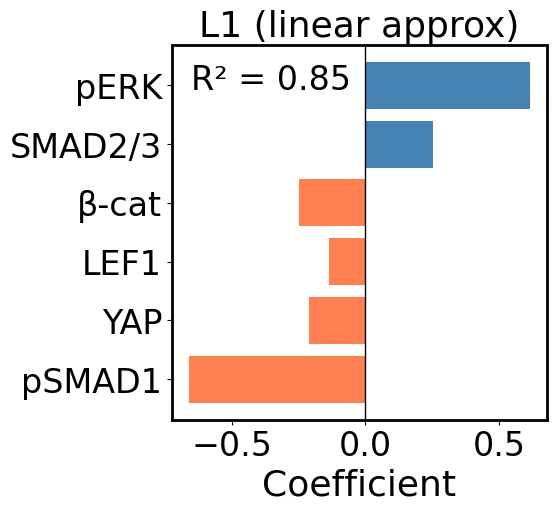

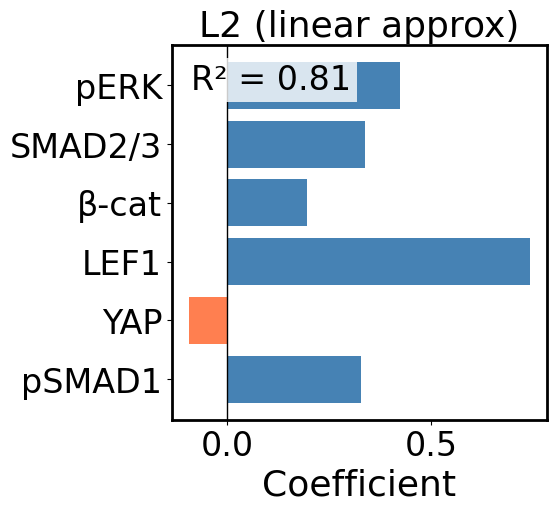

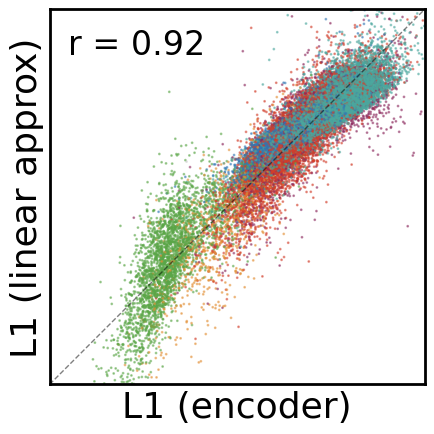

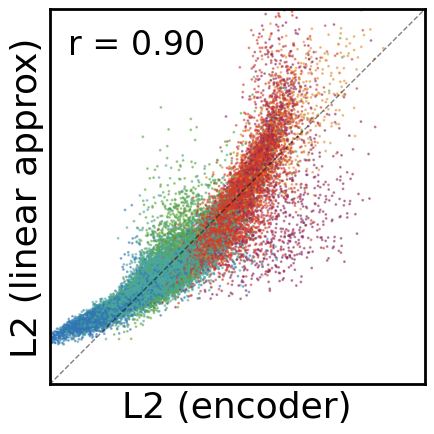

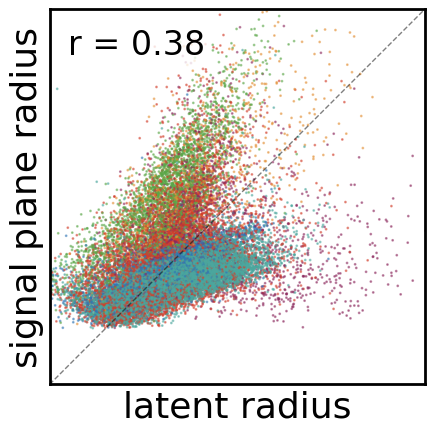

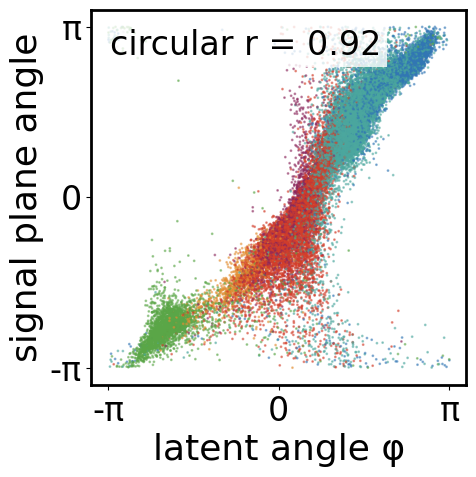

In [220]:
def circular_correlation(a, b):
    """Circular correlation coefficient for two arrays of angles (in radians)."""
    sin_a = np.sin(a - np.mean(a))
    sin_b = np.sin(b - np.mean(b))
    r = np.sum(sin_a * sin_b) / np.sqrt(np.sum(sin_a**2) * np.sum(sin_b**2))
    return r

def circular_difference(a, b):
    """Elementwise difference wrapped to [-pi, pi]."""
    diff = a - b
    return np.arctan2(np.sin(diff), np.cos(diff))
    
# ============================================================
# PLOTS
# ============================================================

fates_data, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates_data]

tol = (0.1, 99.9)
box_size = 0.75

ylabels = [clean_signal_names[s] for s in signals]

# ---- coefficient plots ----
for name, coef, r2 in [('L1 (linear approx)', w1_norm, r2_L1), ('L2 (linear approx)', w2_norm, r2_L2)]:

    fig, ax = plt.subplots(figsize=(5, 5))
    colors_bar = ['steelblue' if c >= 0 else 'coral' for c in coef]
    ax.barh(range(len(signals)), coef, color=colors_bar)
    ax.axvline(x=0, color='k', linewidth=1)
    ax.set_yticks(range(len(signals)))
    ax.set_yticklabels(ylabels, fontsize=fs)
    ax.set_xlabel('Coefficient', fontsize=fs)
    ax.set_title(f'{name}', fontsize=fs)
    ax.text(0.05, 0.95, f'R² = {r2:.2f}',
            transform=ax.transAxes, fontsize=fs - 2,
            va='top', ha='left',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.tick_params(labelsize=fs - 2)
    ax.set_box_aspect(1)
    ax.set_position([0.3, 0.15, box_size, box_size])
    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    if save:
        plt.savefig(f'FigS7/orthogonal_optimized_coef_{name}_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
    plt.show()

# ---- L1/L2 scatter plots ----
for orig, pred, name in [(L1, L1_pred, 'L1'), (L2, L2_pred, 'L2')]:

    fig, ax = plt.subplots(figsize=(5, 5))

    orig_s = (orig - orig.mean()) / orig.std()
    pred_s = (pred - pred.mean()) / pred.std()
    r_val, _ = sp.stats.pearsonr(orig_s, pred_s)

    ax.scatter(orig_s, pred_s, c=colors, s=1, alpha=0.5)

    xmin, xmax = np.percentile(orig_s, tol)
    ymin, ymax = np.percentile(pred_s, tol)
    lim_min = min(xmin, ymin)
    lim_max = max(xmax, ymax)

    ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', linewidth=1, alpha=0.5)
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_xlabel(f'{name} (encoder)', fontsize=fs)
    ax.set_ylabel(f'{name} (linear approx)', fontsize=fs)
    #ax.set_title(f'{name}', fontsize=fs)
    ax.text(0.05, 0.95, f'r = {r_val:.2f}',
            transform=ax.transAxes, fontsize=fs - 2,
            va='top', ha='left',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_box_aspect(1)
    ax.set_position([0.15, 0.15, box_size, box_size])
    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    if save:
        plt.savefig(f'FigS7/orthogonal_optimized_scatter_{name}_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
    plt.show()

# ---- radius plot ----

r_polar = np.sqrt(x_centered**2 + y_centered**2)

p1_center = p1.mean()
p2_center = p2.mean()
r_signal = np.sqrt((p1 - p1_center)**2 + (p2 - p2_center)**2)

r_latent_s = (r_polar - r_polar.mean()) / r_polar.std()
r_signal_s = (r_signal - r_signal.mean()) / r_signal.std()

r_corr, _ = sp.stats.pearsonr(r_latent_s, r_signal_s)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(r_latent_s, r_signal_s, c=colors, s=1, alpha=0.5)

xmin, xmax = np.percentile(r_latent_s, tol)
ymin, ymax = np.percentile(r_signal_s, tol)
lim_min = min(xmin, ymin)
lim_max = max(xmax, ymax)

ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', linewidth=1, alpha=0.5)
ax.set_xlim(lim_min, lim_max)
ax.set_ylim(lim_min, lim_max)
ax.set_xlabel('latent radius', fontsize=fs)
ax.set_ylabel('signal plane radius', fontsize=fs)
ax.text(0.05, 0.95, f'r = {r_corr:.2f}',
        transform=ax.transAxes, fontsize=fs - 2,
        va='top', ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xticks([])
ax.set_yticks([])
ax.set_box_aspect(1)
ax.set_position([0.15, 0.15, box_size, box_size])
for spine in ax.spines.values():
    spine.set_linewidth(sw)

if save:
    plt.savefig('FigS7/orthogonal_optimized_radius_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- angle plot ----
phi_signal = np.arctan2(p2 - p2_center, p1 - p1_center)
r_circ = circular_correlation(theta_corrected, phi_signal)
if r_circ < 0:
    phi_signal = -phi_signal

angles_to_test = np.linspace(-np.pi, np.pi, 360)
mean_abs_diff = []
for shift in angles_to_test:
    diff = circular_difference(theta_corrected, phi_signal + shift)
    mean_abs_diff.append(np.mean(np.abs(diff)))
best_shift = angles_to_test[np.argmin(mean_abs_diff)]

best_shift = 0.8

phi_signal_shifted = np.arctan2(np.sin(phi_signal + best_shift),
                                np.cos(phi_signal + best_shift))

r_circ = circular_correlation(theta_corrected, phi_signal_shifted)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(theta_corrected, phi_signal_shifted, c=colors, s=1, alpha=0.5)
ax.set_xlabel('latent angle φ', fontsize=fs)
ax.set_ylabel('signal plane angle', fontsize=fs)
ax.text(0.05, 0.95, f'circular r = {r_circ:.2f}',
        transform=ax.transAxes, fontsize=fs - 2,
        va='top', ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xticks([-np.pi, 0, np.pi])
ax.set_xticklabels(['-π', '0', 'π'], fontsize=fs - 2)
ax.set_yticks([-np.pi, 0, np.pi])
ax.set_yticklabels(['-π', '0', 'π'], fontsize=fs - 2)
ax.set_box_aspect(1)
ax.set_position([0.15, 0.15, box_size, box_size])
for spine in ax.spines.values():
    spine.set_linewidth(sw)

if save:
    plt.savefig('FigS7/orthogonal_optimized_angle_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
plt.show()

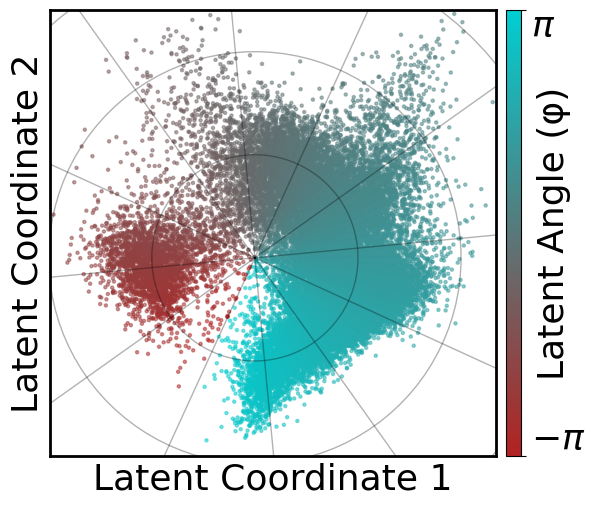

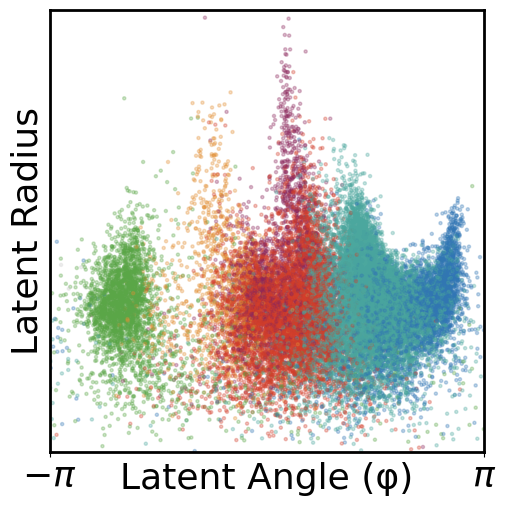

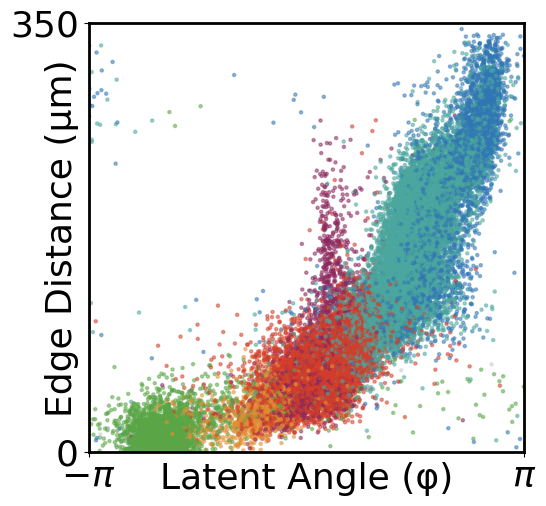

In [221]:
#=============VISUALIZATION=================
save = True

# Set consistent figure parameters
figsize = (5, 5)
fs = 26
sw = 2
s =5

fates_data, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates_data]
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', ['firebrick', 'darkturquoise'], N=100)


#============= (polar overlay with colorbar)=================
fig, ax = plt.subplots(1, 1, figsize=figsize)

xlim_orig = (L1smin, L1smax) 
ylim_orig = (L2smin, L2smax) 
#xlim_orig = (L1_scaled.min(), L1_scaled.max())
#ylim_orig = (L2_scaled.min(), L2_scaled.max())

scatter = ax.scatter(L1_scaled, L2_scaled, c=theta_corrected, s=s, alpha=0.5, 
                     cmap=cmap, vmin=-np.pi, vmax=np.pi)

# Add polar grid lines
lw = 1
r_grid_values = np.linspace(0, r.max(), 6)
for r_val in r_grid_values[1:]:
    theta_circle = np.linspace(-np.pi, np.pi, 100)
    x_circle = center_x + r_val * np.cos(theta_circle)
    y_circle = center_y + r_val * np.sin(theta_circle)
    ax.plot(x_circle, y_circle, 'k-', linewidth=lw, alpha=0.3)

theta_grid_values = np.linspace(-np.pi, np.pi, 13)[:-1]
r_max = r.max() * 1.1
for theta_corrected_val in theta_grid_values:
    theta_raw_val = -(theta_corrected_val) + gap_angle + np.pi
    x_ray = [center_x, center_x + r_max * np.cos(theta_raw_val)]
    y_ray = [center_y, center_y + r_max * np.sin(theta_raw_val)]
    ax.plot(x_ray, y_ray, 'k-', linewidth=lw, alpha=0.3)

ax.set_xlim(xlim_orig)
ax.set_ylim(ylim_orig)
ax.set_xlabel('Latent Coordinate 1', fontsize=fs)
ax.set_ylabel('Latent Coordinate 2', fontsize=fs)
#ax.set_aspect('equal', adjustable='box')
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(sw)

# Apply tight_layout first to set axis positions
plt.tight_layout(pad=0.5)

# Get the axis position after tight_layout
pos = ax.get_position()

# Create a ScalarMappable for the colorbar with full opacity
import matplotlib.cm as cm
norm = mcolors.Normalize(vmin=-np.pi, vmax=np.pi)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Create colorbar from the ScalarMappable instead of the scatter
cbar_ax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.03, pos.height])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_ticks([-np.pi, np.pi])
cbar.set_ticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
cbar.set_label('Latent Angle (φ)', fontsize=fs, rotation=90, labelpad=-35)

tick_labels = cbar.ax.get_yticklabels()
tick_labels[0].set_verticalalignment('bottom')
tick_labels[1].set_verticalalignment('top')

if save:
    plt.savefig('Fig3/LS_polaroverlay_'  + str(len(signals))+ '_run' + str(run)   + 'D' + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()
plt.close()

#============= (polar space)=================
fig, ax = plt.subplots(1, 1, figsize=figsize)

r_max = np.percentile(r, 99.99)*1.1

ax.scatter(theta_corrected, r, c=colors, s=s, alpha=0.3)
ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
ax.set_ylabel('Latent Radius', fontsize=fs)
ax.set_xlim(-np.pi, np.pi)
ax.set_ylim([0,r_max/1.1])
ax.set_xticks([-np.pi, np.pi])
ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
ax.set_yticks([])
ax.tick_params(axis='x', which='major', pad=2)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

#ax.set_aspect('equal', adjustable='box')
plt.tight_layout(pad=0.5)
if save:
    plt.savefig('Fig3/LS_polar_'  + str(len(signals)) + 'D' + '_run' + str(run)   + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()
plt.close()

#============= (angle vs radius)=================
fig, ax = plt.subplots(1, 1, figsize=(5.4,5))

ax.scatter(theta_corrected, data.loc[mask, 'CircleEdgeDist'], c=colors, s=s, alpha=0.5)
ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
ax.set_ylabel('Edge Distance (μm)', fontsize=fs, labelpad=-50)
ax.set_xlim(-np.pi, np.pi)
ax.set_ylim(0, 350)
ax.set_xticks([-np.pi, np.pi])
ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
ax.set_yticks([0, 350])
ax.set_yticklabels([0, 350], fontsize=fs)
ax.tick_params(axis='x', which='major', pad=2)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout(pad=0.5)
if save:
    plt.savefig('Fig3/LS_angle_v_radius_'  + str(len(signals)) + 'D' + '_run' + str(run)  + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()
plt.close()

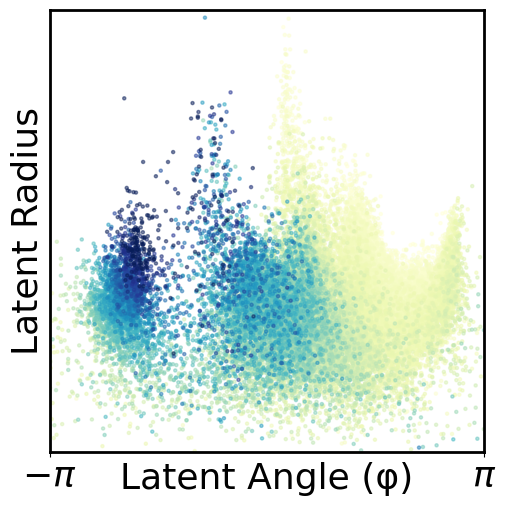

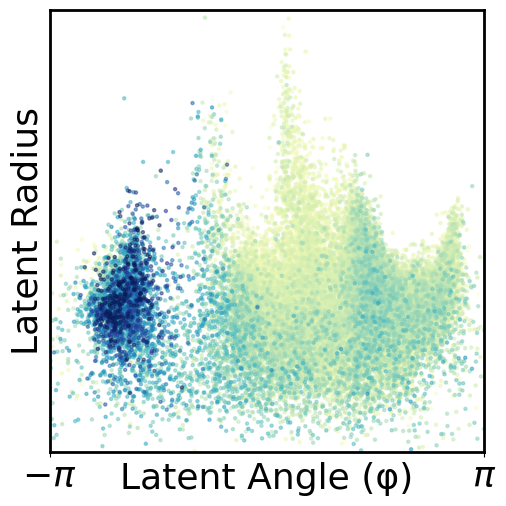

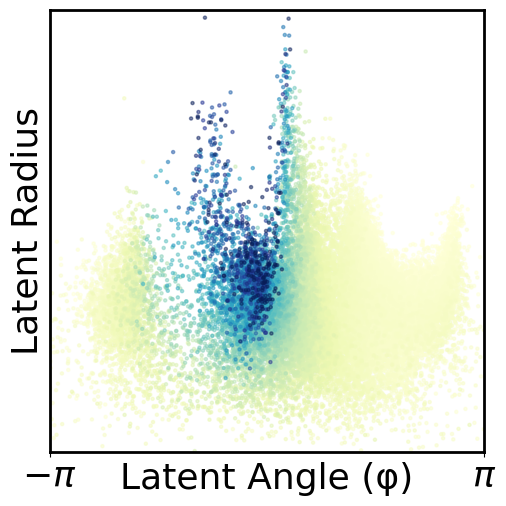

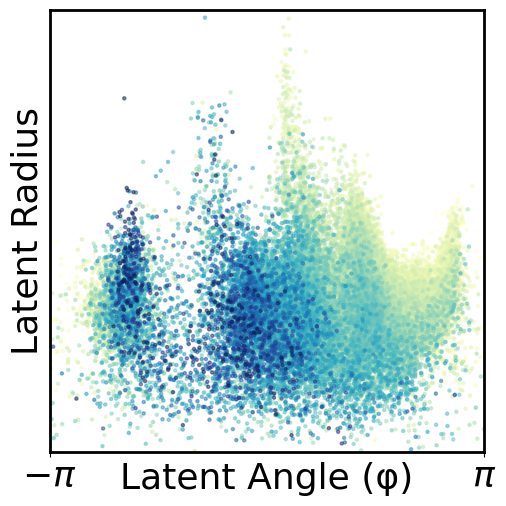

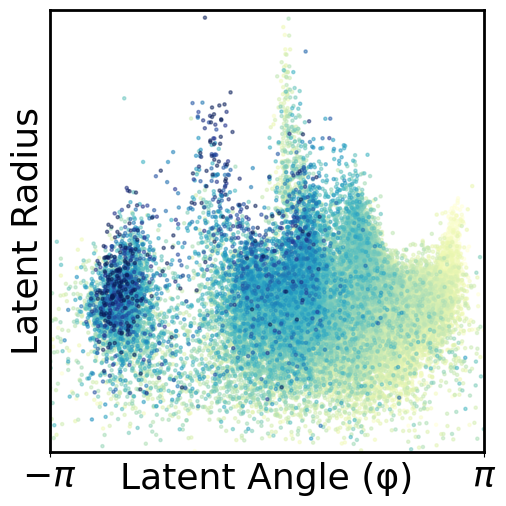

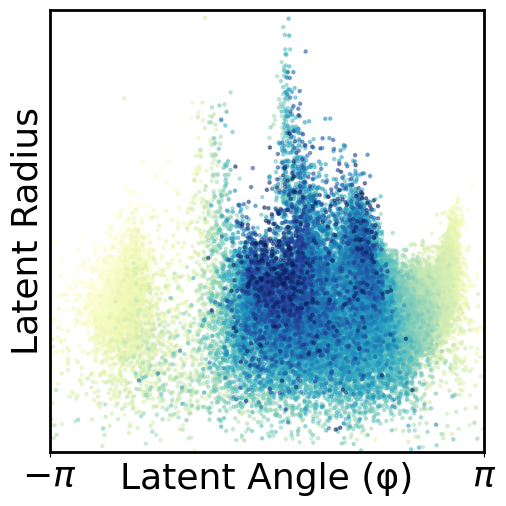

In [222]:
#=============VISUALIZATION=================

# Set consistent figure parameters
figsize = (5, 5)
fs = 26
sw = 2
s = 5

r_max = np.percentile(r, 99.99)*1.1

#============= (polar space)=================

for sig in signals:
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    colors = data.loc[mask, sig]
    order = colors.sort_values().index
    tol=(0.5,99.5)
    vmin = np.percentile(colors, tol[0])
    vmax = np.percentile(colors, tol[1])
    ax.scatter(theta_corrected[order], r[order],c=colors[order], s=s, cmap='YlGnBu',vmin=vmin,vmax=vmax, alpha=0.5)
    
    ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
    ax.set_ylabel('Latent Radius', fontsize=fs)
    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim([0,r_max/1.1])
    ax.set_xticks([-np.pi, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
    ax.set_yticks([])
    ax.tick_params(axis='x', which='major', pad=2)
    
    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    
    #ax.set_aspect('equal', adjustable='box')
    plt.tight_layout(pad=0.5)
    if save:
        plt.savefig('FigS7/LS_polar_'+sig+ str(len(signals)) + 'D' + '_run' + str(run)  + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
    plt.show()
    plt.close()

99.0% of data points are inside the contours


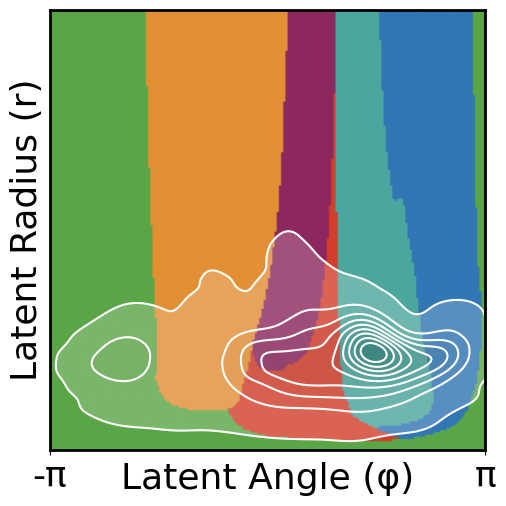

In [223]:
# EXTRAPOLATE FATE MAP IN POLAR COORDINATES

# Create polar coordinate grid
n_theta = 200
n_r = 200

theta_grid = np.linspace(-np.pi, np.pi, n_theta)
r_grid = np.linspace(0, r.max(), n_r)  # Extend slightly beyond data

THETA_GRID, R_GRID = np.meshgrid(theta_grid, r_grid)

# Apply the SAME correction as theta_corrected: rotate and negate
# Reverse the correction to get back to raw angles for Cartesian conversion
THETA_RAW = -(THETA_GRID) - np.pi + gap_angle

# Convert polar grid back to Cartesian latent space using raw angles
L1_from_polar = center_x + R_GRID * np.cos(THETA_RAW)
L2_from_polar = center_y + R_GRID * np.sin(THETA_RAW)

# Flatten for model prediction
mugrid_polar = np.stack([L1_from_polar.ravel(), L2_from_polar.ravel()], axis=1)
mugrid_polar = torch.FloatTensor(mugrid_polar).to(device)

# Get predictions
model.eval() 
with torch.no_grad():
    Y_polar = model.decode(mugrid_polar).cpu().numpy()
    Y_polar = vib_choice.scaler_Y_run.inverse_transform(Y_polar)
    Y_polar = pd.DataFrame(Y_polar, columns=gene_names)
    
fates_polar, _ = IIF.return_fates(Y_polar, thresh=thresh)

# Create RGB image for polar fate map
rgb_image_polar = np.zeros((n_r, n_theta, 3))

for i, fate in enumerate(fates_polar):
    color = IIF.colmap_fates[fate]
    rgb = mcolors.to_rgb(color)
    rgb_image_polar[i // n_theta, i % n_theta] = rgb

#--------COMPUTE KDE IN CORRECTED POLAR SPACE--------------

# Compute KDE for the scatter points in polar coordinates
if len(theta_corrected) > 1:
    # Create KDE in corrected polar space
    values_polar = np.vstack([theta_corrected, r])
    kernel_polar = sp.stats.gaussian_kde(values_polar, bw_method=0.2)
    
    # Evaluate KDE at the actual data points
    kde_at_data = kernel_polar(values_polar)
    
    # Set vmin so that X% of data points are outside the contours
    data_percentile = 1  # Change this: 10 means 10% of data outside, 90% inside
    vmin = np.percentile(kde_at_data, data_percentile)
    
    # Evaluate KDE on the polar grid
    kde_grid_polar = kernel_polar(np.vstack([THETA_GRID.ravel(), R_GRID.ravel()]))
    kde_grid_polar = kde_grid_polar.reshape(THETA_GRID.shape)
    
    # Define contour levels from vmin to max
    vmax = kde_grid_polar.max()
    levels = np.linspace(vmin, vmax, 10)
    
    # Verify
    fraction_inside = np.sum(kde_at_data >= vmin) / len(theta_corrected)
    print(f"{fraction_inside*100:.1f}% of data points are inside the contours")

#--------RECTANGULAR PLOT WITH POLAR COORDINATES (SQUARE)--------------

fs = 26
sw = 2
s = 5

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

# Display fate map with theta on x-axis and r on y-axis
ax.imshow(rgb_image_polar, origin='lower', aspect='auto',
          extent=[theta_grid.min(), theta_grid.max(), r_grid.min(), r_grid.max()])

# Add KDE contours
if len(theta_corrected) > 1:
    ax.contourf(THETA_GRID, R_GRID, kde_grid_polar, 
                levels=levels, cmap='Greys', alpha=0.2)
    ax.contour(THETA_GRID, R_GRID, kde_grid_polar, 
               levels=levels, colors='white', linewidths=1.5)

# Formatting
ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
ax.set_ylabel('Latent Radius (r)', fontsize=fs)
ax.set_xlim(theta_grid.min(), theta_grid.max())
ax.set_ylim(0, r_grid.max())

# Optional: Add custom tick labels
theta_labels = ['-π', 'π']
ax.set_xticks([-np.pi, np.pi])
ax.set_xticklabels(theta_labels, fontsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(sw)

# Force square aspect ratio
#ax.set_aspect('equal', adjustable='box')

plt.tight_layout(pad=0.5)
if save:
    plt.savefig('Fig3/LS_fate_polar_rectangular' + str(len(signals)) + 'D' + '_run' + str(run)  + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()




Inner: 3527 cells


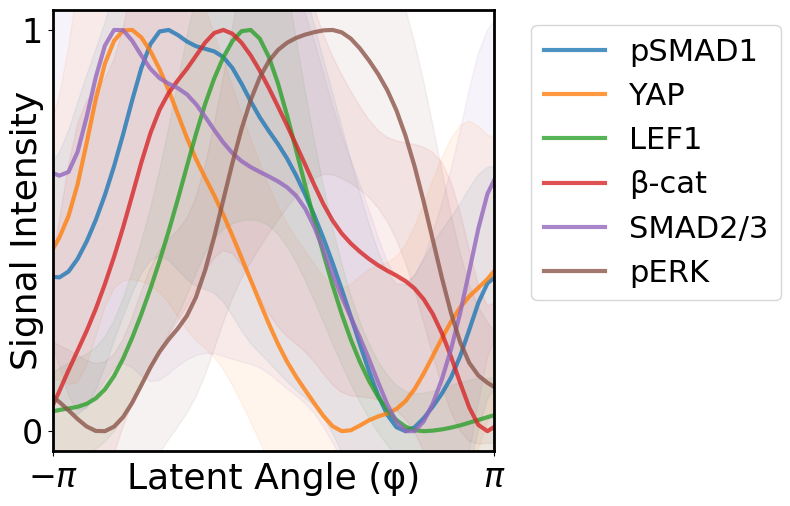


Outer: 26904 cells


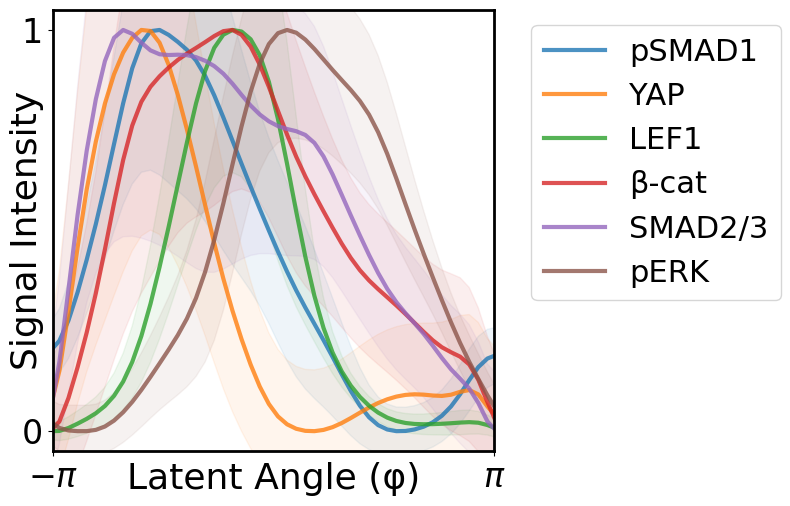


All: 30431 cells


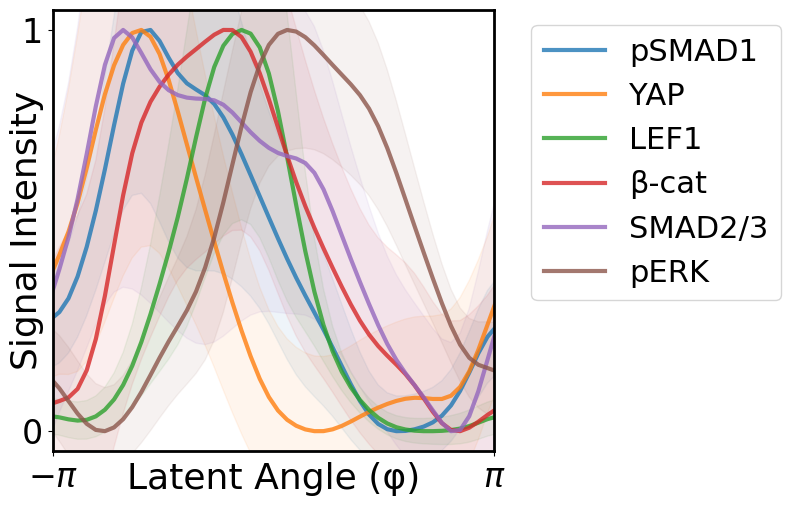

In [224]:
#=============PLOT SIGNAL MEANS VS POLAR ANGLE (NORMALIZED 0-1, SMOOTHED WITH PERIODIC BC)=================

save = True

import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Number of angular bins
n_bins = 50

# Create bins for theta
theta_bins = np.linspace(-np.pi-0.1, np.pi+0.1, n_bins + 1)
theta_centers = (theta_bins[:-1] + theta_bins[1:]) / 2

# Initialize storage for mean signals
signal_means = {signal: np.zeros(n_bins) for signal in signals}
signal_stds = {signal: np.zeros(n_bins) for signal in signals}
bin_counts = np.zeros(n_bins)

# Compute means and stds for each bin
for i in range(n_bins):
    mask_bin = (theta_corrected >= theta_bins[i]) & (theta_corrected < theta_bins[i+1])
    bin_counts[i] = mask_bin.sum()
    
    if mask_bin.sum() > 0:
        for signal in signals:
            signal_values = data.loc[mask, signal].values[mask_bin]
            signal_means[signal][i] = signal_values.mean()
            signal_stds[signal][i] = signal_values.std()

# Normalize each signal to 0-1 range
signal_means_norm = {}
signal_stds_norm = {}
signal_means_smooth = {}

for signal in signals:
    min_val = signal_means[signal].min()
    max_val = signal_means[signal].max()
    range_val = max_val - min_val
    
    if range_val > 0:
        signal_means_norm[signal] = (signal_means[signal] - min_val) / range_val
        signal_stds_norm[signal] = signal_stds[signal] / range_val
    else:
        signal_means_norm[signal] = signal_means[signal]
        signal_stds_norm[signal] = signal_stds[signal]
    
    # Apply smoothing with periodic boundary conditions
    # Extend the array by wrapping values at both ends
    extended = np.concatenate([
        signal_means_norm[signal][-5:],  # Last 5 points
        signal_means_norm[signal],
        signal_means_norm[signal][:5]    # First 5 points
    ])
    smoothed_extended = gaussian_filter1d(extended, sigma=2)
    signal_means_smooth[signal] = smoothed_extended[5:-5]  # Extract middle portion


#=============STRATIFIED OVERLAY BY RADIAL POSITION (MEAN, NORMALIZE AFTER SMOOTHING)============


# Define three radial bands based on std around mean
r_mean = np.mean(r)
r_std = np.std(r)

r1 = 1
r2 = 5
radial_conditions = [
    (r <  r1, f'Inner'),
#    ((r >= r1) & (r <= r2), f'Middle (mean ± σ)'),
    (r > r1, f'Outer'),
    (r>0, 'All')
]

for (r_condition, r_label) in radial_conditions:

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    
    print(f"\n{r_label}: {r_condition.sum()} cells")
    
    if r_condition.sum() == 0:
        ax.text(0.5, 0.5, 'No cells', ha='center', va='center', transform=ax.transAxes)
        continue
    
    # Compute binned means for this radial slice
    signal_means_r = {signal: np.zeros(n_bins) for signal in signals}
    signal_stds_r = {signal: np.zeros(n_bins) for signal in signals}
    
    for i in range(n_bins):
        mask_bin = (theta_corrected >= theta_bins[i]) & \
                   (theta_corrected < theta_bins[i+1]) & r_condition
        
        if mask_bin.sum() > 0:
            for signal in signals:
                signal_values = data.loc[mask, signal].values[mask_bin]
                signal_means_r[signal][i] = signal_values.mean()
                signal_stds_r[signal][i] = signal_values.std()
    
    # FIRST smooth with periodic BC, THEN normalize
    signal_means_r_smooth = {}
    signal_stds_r_smooth = {}
    signal_means_r_norm = {}
    signal_stds_r_norm = {}
    
    for signal in signals:
        # Smooth FIRST with periodic boundary conditions
        extended = np.concatenate([
            signal_means_r[signal][-5:],
            signal_means_r[signal],
            signal_means_r[signal][:5]
        ])
        smoothed_extended = gaussian_filter1d(extended, sigma=2)
        signal_means_r_smooth[signal] = smoothed_extended[5:-5]
        
        # Smooth standard deviations too
        extended_std = np.concatenate([
            signal_stds_r[signal][-5:],
            signal_stds_r[signal],
            signal_stds_r[signal][:5]
        ])
        smoothed_std_extended = gaussian_filter1d(extended_std, sigma=2)
        signal_stds_r_smooth[signal] = smoothed_std_extended[5:-5]
        
        # NOW normalize to 0-1 AFTER smoothing
        min_val = signal_means_r_smooth[signal].min()
        max_val = signal_means_r_smooth[signal].max()
        range_val = max_val - min_val
        
        #print(f"  {signal}: smoothed range [{min_val:.3f}, {max_val:.3f}]")
        
        if range_val > 0:
            signal_means_r_norm[signal] = (signal_means_r_smooth[signal] - min_val) / range_val
            signal_stds_r_norm[signal] = signal_stds_r_smooth[signal] / range_val
        else:
            signal_means_r_norm[signal] = np.ones_like(signal_means_r_smooth[signal]) * 0.5
            signal_stds_r_norm[signal] = signal_stds_r_smooth[signal]
        
        #print(f"    After normalization: [{signal_means_r_norm[signal].min():.3f}, {signal_means_r_norm[signal].max():.3f}]")
    
    # Now plot all signals for this radial band
    for i,signal in enumerate(signals):
        # Plot
        line = ax.plot(theta_centers, signal_means_r_norm[signal], '-', 
                      linewidth=3, label=clean_signal_names[signal], alpha=0.8)
        
        color = line[0].get_color()
        
        ax.fill_between(theta_centers, 
                       signal_means_r_norm[signal] - signal_stds_r_norm[signal],
                       signal_means_r_norm[signal] + signal_stds_r_norm[signal],
                       alpha=0.075, color=color)
    
    ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
    ax.set_ylabel('Signal Intensity', fontsize=fs, labelpad=-16)
    
    # Set x-axis to show only -π and π
    ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks([-np.pi, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs-2)
    
    # Set y-axis to show only 0 and 1
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['0', '1'], fontsize=fs-2)
    
    # Make the axes box physically square
    ax.set_box_aspect(1)
    
    #ax.grid(True, alpha=0.3)
    ax.legend(fontsize=fs-4, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    plt.tight_layout(pad=0.5)
    if save:
        plt.savefig('FigS7/all_signals_vs_polar_angle_normalized_'+r_label+str(len(signals)) + 'D' + '_run' + str(run)  +'.png', dpi=300, bbox_inches='tight')
    plt.show()


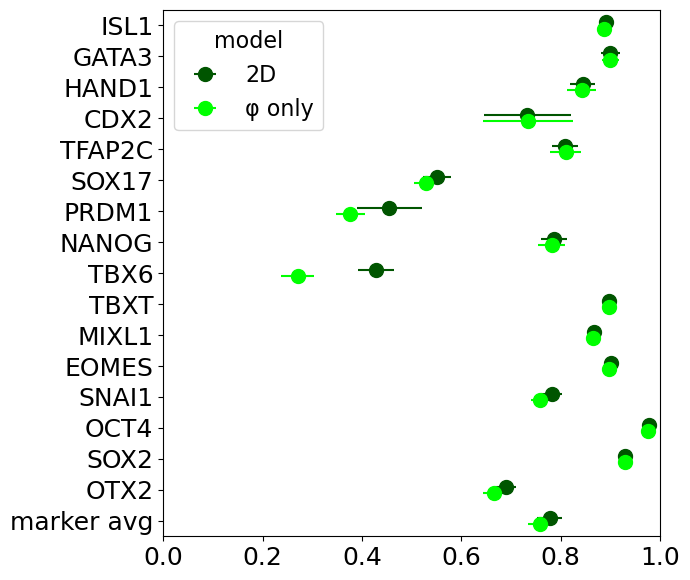

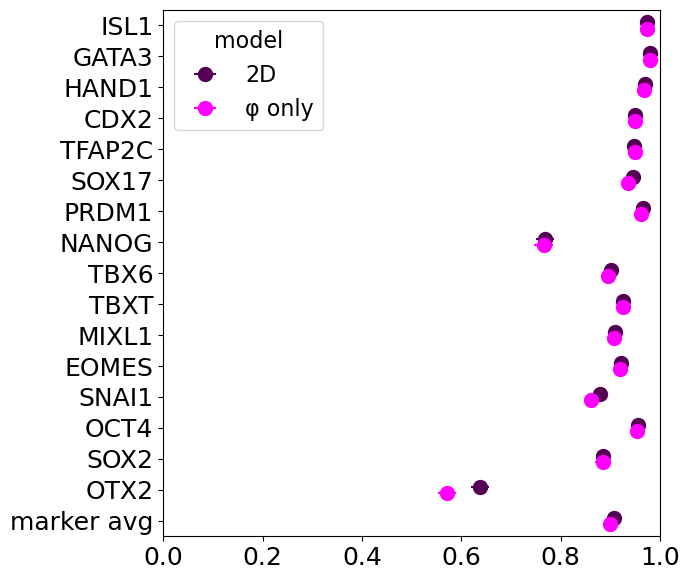

In [225]:
# ============================================================
# THETA-ONLY PREDICTION: use mean (L1, L2) within theta bins
# i.e. for each cell, predict using the centroid of its theta bin
# ============================================================


n_theta_bins = 100

# bin cells by theta
theta_bins = pd.cut(theta_corrected, bins=n_theta_bins, labels=False)

# for each cell, replace its latent coords with the mean of its theta bin
L1_theta_mean = np.zeros_like(L1)
L2_theta_mean = np.zeros_like(L2)

for b in range(n_theta_bins):
    idx = theta_bins == b
    if idx.sum() > 0:
        L1_theta_mean[idx] = L1[idx].mean()
        L2_theta_mean[idx] = L2[idx].mean()

# decode using both full and bin-mean latent coordinates
model.eval()
with torch.no_grad():

    # --- full prediction ---
    mu_full = torch.FloatTensor(
        np.stack([L1, L2], axis=1)
    ).to(device)
    Y_full_z = model.decode(mu_full).cpu().numpy()
    Y_full = vib_choice.scaler_Y_run.inverse_transform(Y_full_z)
    Y_full = pd.DataFrame(Y_full, columns=gene_names, index=data[mask].index)

    # --- theta-only prediction ---
    mu_theta = torch.FloatTensor(
        np.stack([L1_theta_mean, L2_theta_mean], axis=1)
    ).to(device)
    Y_theta_z = model.decode(mu_theta).cpu().numpy()
    Y_theta = vib_choice.scaler_Y_run.inverse_transform(Y_theta_z)
    Y_theta = pd.DataFrame(Y_theta, columns=gene_names, index=data[mask].index)

# wrap back into full dataframe for calcPerformance
pred_full_wrapped = data[mask].copy()
pred_full_wrapped[gene_names] = Y_full[gene_names]

pred_theta_wrapped = data[mask].copy()
pred_theta_wrapped[gene_names] = Y_theta[gene_names]

pred_subs_compare = {
    'full':       {'avg': pred_full_wrapped},
    'theta_only': {'avg': pred_theta_wrapped},
}

performances_compare, _ = IIF.calcPerformance(data[mask], pred_subs_compare, thresh, gene_names)

# ============================================================
# PLOT: phi-only vs full - matching original plot style
# ============================================================

cond = 'B50'
labels = markers + ['marker_avg']

for score in ['f1', 'acc']:

    fig, ax = plt.subplots(figsize=(7, 0.3 * len(labels) + 0.8))
    fs = 18
    ms = 10

    if score == 'f1':
        c = np.array([0, 1, 0])
    else:
        c = np.array([1, 0, 1])

    # divisor controls shade: smaller = darker
    model_styles = {
        'full':       {'divisor': 3, 'offset': -0.1},
        'theta_only': {'divisor': 1, 'offset':  0.1},  # lighter
    }

    for model_key, style in model_styles.items():

        col_avg = f'{model_key}-{score}-avg'
        col_std = f'{model_key}-{score}-std'

        available = [l for l in labels
                     if col_avg in performances_compare[cond].columns
                     and not pd.isna(performances_compare[cond].loc[l, col_avg])]

        means = performances_compare[cond].loc[available, col_avg]
        stds  = performances_compare[cond].loc[available, col_std]
        ypos  = [labels.index(l) + style['offset'] for l in available]

        ax.errorbar(means, ypos, xerr=stds,
                    fmt='o',
                    color=c / style['divisor'],
                    ms=ms)

    labels_tick = labels.copy()
    labels_tick[-1] = 'marker avg'

    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.set_yticks(range(len(labels)), labels_tick)
    ax.tick_params(axis='both', labelsize=fs)
    ax.set_ylim([-0.5, len(labels) - 0.5])
    ax.set_xlim([0, 1])
    plt.gca().invert_yaxis()
    plt.tight_layout()

    plt.legend(['2D', 'φ only'], fontsize=fs-2, title='model', title_fontsize=fs-2)

    plt.savefig(f'FigS7/phi_vs_full_{score}_comparison'+ str(len(signals)) + 'D' + '_run' + str(run)  +'.png', dpi=150)
    plt.show()

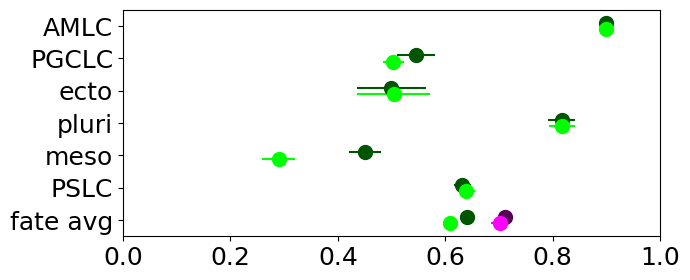

In [226]:
# ============================================================
# PLOT: phi-only vs full - FATE labels
# ============================================================

cond = 'B50'

otherlabels = [l for l in performances_compare[cond].index if l not in markers + ['marker_avg']]
otherlabels = otherlabels[1:] + [otherlabels[0]]
labels = otherlabels

fig, ax = plt.subplots(figsize=(7, 0.3 * len(labels) + 0.8))
fs = 18
ms = 10

for score in ['f1', 'acc']:

    if score == 'f1':
        c = np.array([0, 1, 0])
    else:
        c = np.array([1, 0, 1])

    for model_key, style in model_styles.items():

        col_avg = f'{model_key}-{score}-avg'
        col_std = f'{model_key}-{score}-std'

        available = [l for l in labels
                     if col_avg in performances_compare[cond].columns
                     and not pd.isna(performances_compare[cond].loc[l, col_avg])]

        means = performances_compare[cond].loc[available, col_avg]
        stds  = performances_compare[cond].loc[available, col_std]
        ypos  = [labels.index(l) + style['offset'] for l in available]

        ax.errorbar(means, ypos, xerr=stds,
                    fmt='o',
                    color=c / style['divisor'],
                    ms=ms)

labels_tick = labels.copy()
labels_tick[-1] = 'fate avg'

ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
ax.set_yticks(range(len(labels)), labels_tick)
ax.tick_params(axis='both', labelsize=fs)
ax.set_ylim([-0.5, len(labels) - 0.5])
ax.set_xlim([0, 1])
plt.gca().invert_yaxis()
plt.tight_layout()
#plt.legend(['2D', 'φ only'], fontsize=fs-2, title='model', title_fontsize=fs-2)

plt.savefig('FigS7/phi_vs_full_fate_comparison'+ str(len(signals)) + 'D' + '_run' + str(run)  +'.png', dpi=150)
plt.show()

### 1D latent coordinate

In [121]:
# 1D performance
# run VIB with 6-fold cross-validation for B50 and using all B50 data to predict perturbations

import torch
import warnings
from sklearn.exceptions import InconsistentVersionWarning
import time
import importlib
importlib.reload(IIF)

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
N_run = 3

feat_names = signals

for Ldim in [1,2]:
    
    for Nlay in [2]:
        
        for Nhid in [32]:
        
            hyperparam = {'HIDDEN_DIM':Nhid, 'N_LAYERS':Nlay, 'LATENT_DIM': Ldim}
            
            for it in range(N_run):
            
                print(f"  Run {it}/{N_run}")
                start = time.time()
                
                pred_df = data.copy()    
                data_cond = data[data['condition']=='B50']
            
                # first predict each colony in B50 based on the other colonies
                
                colony_idx = np.unique(data_cond['Colony'])
                for test_colony in colony_idx:
            
                    print('B50 col: ' + str(test_colony))
                    
                    # split data into test and train by colonies
                    train_colonies = np.setdiff1d(colony_idx, test_colony)
                    data_test = data_cond[data_cond['Colony'].isin([test_colony])]
                    data_train = data_cond[data_cond['Colony'].isin(train_colonies)]
    
                    feat_train = data_train[feat_names] # signal_names[:-1]
                    feat_test = data_test[feat_names]
                    tar_train = data_train[gene_names]
            
                    # run VIB
                    vib1D = IIF.VIB(feat_train, tar_train, hyperparam)
                    _ = vib1D.train(verbose=False)
                    tar_predict = vib1D.predict(feat_test)
                    pred_df.loc[tar_predict.index, tar_predict.columns] = tar_predict
            
                # then predict other conditions based on all B50 colonies
                data_train = data_cond
                feat_train = data_train[feat_names]
                tar_train = data_train[gene_names] 
                vib1D = IIF.VIB(feat_train, tar_train, hyperparam)
                
                for cond in [c for c in conditions if c != 'B50']:
            
                    print(cond)
            
                    data_cond = data[data['condition']==cond]
                    feat_test = data_cond[feat_names]
                    tar_predict = vib1D.predict(feat_test)
                    pred_df.loc[tar_predict.index, tar_predict.columns] = tar_predict
        
                pred_df.to_csv(dataDir + '/VIB_sweep/260307_VIB_' + str(len(feat_names)) + 'D_B50_Nhid' + str(Nhid) + '_Nlay'+ str(hyperparam['N_LAYERS']) + '_Ldim' + str(hyperparam['LATENT_DIM']) +'_run' + str(it) + '.csv')
            
                end = time.time()
                print(f"Elapsed time: {end - start} seconds")

  Run 0/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 63.29533839225769 seconds
  Run 1/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 63.50594186782837 seconds
  Run 2/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 58.83660268783569 seconds
  Run 0/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 64.66402840614319 seconds
  Run 1/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 64.1199791431427 seconds
  Run 2/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 65.73974251747131 seconds


In [227]:
# LOAD RUNS FOR HIDDEN_DIM, N_LAYERS, LATENT_DIM OPTIMIZATION FROM CSV 

N_run = 3
feat_names = signals #signal_names

pred_subs = dict()
avg_pred = dict()

for Ldim in [1,2]:
    
    for Nlay in [2]:
        
        for Nhid in [32]:

            hyperparam = {'HIDDEN_DIM':Nhid, 'N_LAYERS':Nlay, 'LATENT_DIM': Ldim}
            
            pred_subs[(Nhid, Nlay, Ldim)] = dict()
            
            for it in range(N_run):
            
                pred_df = pd.read_csv(dataDir + '/VIB_sweep/260307_VIB_' + str(len(feat_names)) + 'D_B50_Nhid' + str(hyperparam['HIDDEN_DIM']) + '_Nlay'+ str(hyperparam['N_LAYERS']) + '_Ldim' + str(hyperparam['LATENT_DIM']) +'_run' + str(it) + '.csv', index_col=0) 
                pred_subs[(Nhid, Nlay, Ldim)][it] = pred_df
        
            # average the runs
            avg_pred = pred_subs[(Nhid, Nlay, Ldim)][0].copy()
            dfs_pred_genes = [df[gene_names] for df in pred_subs[(Nhid, Nlay, Ldim)].values()]
            avg_pred_genes = pd.concat(dfs_pred_genes).groupby(level=0).mean()
            avg_pred[gene_names] = avg_pred_genes
            pred_subs[(Nhid, Nlay, Ldim)]['avg'] = avg_pred

In [228]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs, thresh, gene_names)

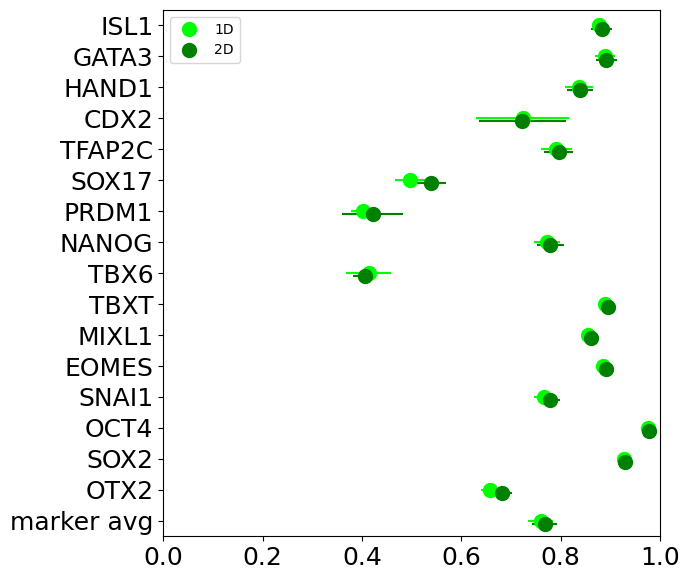

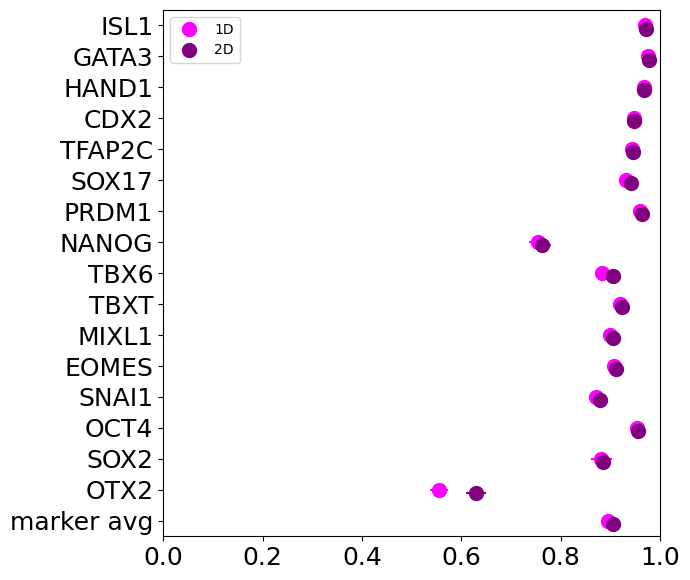

In [229]:
# F1 score and accuracy vs 2D

# plot f1 and accuracy per gene 

cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'marker': labels}
xlim = 1

for prefix, labels in labeldict.items():
    
    for score in ['f1','acc']:

        if score=='f1':
            colors = [(0,1,0),(0,1/2,0)]
        else:
            colors = [(1,0,1),(1/2,0,1/2)]
        
        fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
        fs = 18
        ms = 10

        for ct, k in enumerate(pred_subs.keys(), start=1):
            
            c = colors[ct-1]
            offset = (ct-1)*0.1
                
            means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
            stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
            ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c, ms=ms)
        
        labels_tick = labels.copy()
        labels_tick[-1] = prefix + ' avg'
        ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
        ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
        ax.tick_params(axis='both', labelsize=fs)
        
        ax.set_ylim([-0.5, len(labels) -0.5])
        ax.set_xlim([0, xlim])
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.legend(['1D','2D'], fontsize=10)
        #plt.savefig(dataDir + '/'+prefix+score+'_VIB32-2-2_pSMAD1alone.png') 

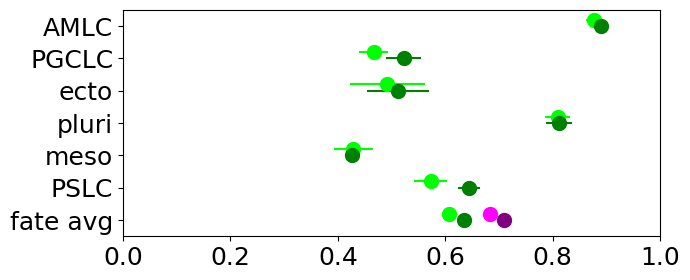

In [138]:
# plot fate f1 and accuracy for Nhid=24, Nlay=2, for different input signals

Nlay = 2
Nhid = 32
    
cond = 'B50'
labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

labeldict = {'fate': otherlabels}

for prefix, labels in labeldict.items():

    fig, ax = plt.subplots(figsize=(7, 0.3*len(labels) + 0.8))
    fs = 18
    ms = 10
    
    for score in ['f1','acc']:

        if score == 'f1':
            c = np.array([0, 1, 0])
        else:
            c = np.array([1, 0, 1])

        for Ldim in [1,2]: 
            
            k = (Nhid,Nlay,Ldim)        
            offset = (Ldim-2)*0.2
        
            means = performances[cond].loc[labels, str(k)+'-'+score+'-avg']
            stds = performances[cond].loc[labels, str(k)+'-'+score+'-std']
            ax.errorbar(means, [i + offset for i in range(len(labels))], xerr=stds, fmt='o', color=c/Ldim, ms=ms)
        
    labels_tick = labels.copy()
    labels_tick[-1] = prefix + ' avg'
    ax.set_xticks([0,0.2,0.4,0.6,0.8,1])
    ax.set_yticks(range(len(labels)), labels_tick)  # Set y-ticks to gene names
    ax.tick_params(axis='both', labelsize=fs)
    
    ax.set_ylim([-0.5, len(labels) -0.5])
    ax.set_xlim([0, xlim])
    plt.gca().invert_yaxis()
    plt.tight_layout()
    #plt.savefig(dataDir + '/'+prefix+score+'_VIB32-2-Ldim_optimize_B50.pdf') 

In [230]:
# GET THE 1D model trained on the full data
N_run = 5
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 1}
genes = gene_names

vib1D = {}

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]

for run in range(0,N_run):
    
    vib1D[run] = IIF.VIB(feat_train, tar_train, hyperparam)
    if not os.path.exists(dataDir + '/model_'+str(run)+ '_' + str(len(signals)) + 'D' + '_Ldim1.pth'):
        print('run VIB')
        _ = vib1D[run].train(verbose=False)
        torch.save(vib1D[run].model, dataDir + '/model_'+str(run)+ '_' + str(len(signals)) + 'D' + '_Ldim1.pth')
    else: 
        print('load VIB')
        vib1D[run].model = torch.load(dataDir + '/model_'+str(run)+ '_' + str(len(signals)) + 'D' + '_Ldim1.pth', weights_only=False)

load VIB
load VIB
load VIB
load VIB
load VIB


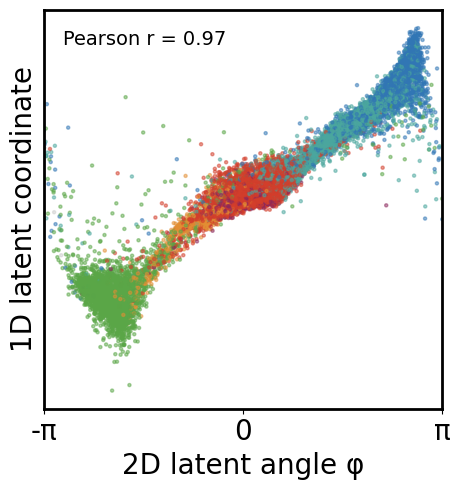

In [231]:
# ============================================================
# PLOT: 1D latent coordinate vs 2D polar angle (theta)
# ============================================================

run = 1  # or whichever run you want
mask = (data['condition'] == cond)

# --- encode with 1D model ---
model1D = vib1D[run].model
X = vib1D[run].scaler_X_run.transform(data.loc[mask, signals])
X = torch.FloatTensor(X).to(device)

model1D.eval()
with torch.no_grad():
    mu1D, _ = model1D.encode(X)
    L1D = mu1D[:, 0].cpu().numpy()

# standardize for plotting
L1D_scaled = (L1D - L1D.mean()) / L1D.std()

# ============================================================
# color by fate
# ============================================================

fates_data, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates_data]

fs = 20
sw = 2
s = 5
alpha = 0.5

fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(theta_corrected, L1D_scaled, c=colors, s=s, alpha=alpha)

r, p = sp.stats.pearsonr(theta_corrected, L1D_scaled)
#print(f'Pearson r = {r:.3f}, p = {p:.3e}')
ax.text(0.05, 0.95, f'Pearson r = {r:.2f}',
        transform=ax.transAxes, fontsize=fs-6,
        va='top', ha='left')
        #bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('2D latent angle φ', fontsize=fs)
ax.set_ylabel('1D latent coordinate', fontsize=fs)
ax.set_xticks([-np.pi, 0, np.pi])
ax.set_xlim([-np.pi, np.pi])
ax.set_xticklabels(['-π', '0', 'π'], fontsize=fs)
ax.set_yticks([])
ax.tick_params(labelsize=fs)
ax.set_box_aspect(1)


for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout()
plt.savefig('FigS7/1D_vs_2D_angle_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150)
plt.show()


### Fatebar vs polar coordinates 

In [232]:
labels, names = IIF.return_fates(data, thresh=thresh)
np.unique(labels)

array(['AMLC', 'PGCLC', 'PSLC', 'ecto', 'meso', 'other', 'pluri'],
      dtype='<U5')

In [233]:
data['threshold_clusters'], _ = IIF.return_fates(data, thresh=thresh)

In [234]:
# get latent coordinates for all cells across conditions

run=12

model = vib_choice.model
X = vib_choice.scaler_X_run.transform(data[signals])
X = torch.FloatTensor(X).to(device)

# 2D model
model.eval() 
with torch.no_grad():
    mu, _ = model.encode(X)

L1 = mu[:, 0].cpu().numpy()
L2 = mu[:, 1].cpu().numpy()

L1_scaled = (L1 - L1mean)/L1std
L2_scaled = (L2 - L2mean)/L1std

#--------------Compute  polar coordinates---------------
x_centered = L1_scaled - center_x
y_centered = L2_scaled - center_y
r = np.sqrt(x_centered**2 + y_centered**2)
theta_raw = np.arctan2(y_centered, x_centered)

# Rotate angles so the gap is at ±π and reverse direction
theta_corrected = -(theta_raw - gap_angle + np.pi)
# Wrap to [-π, π]
theta_corrected = np.arctan2(np.sin(theta_corrected), np.cos(theta_corrected))

data['L_theta'] = theta_corrected
data['L_r'] = r

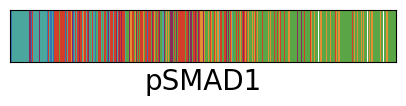

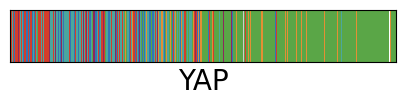

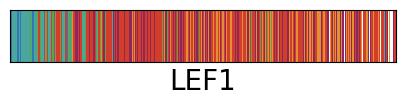

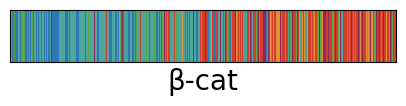

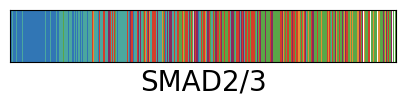

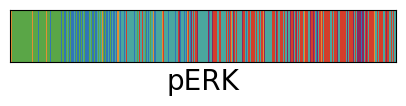

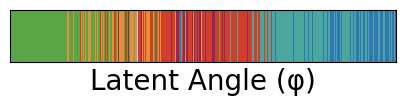

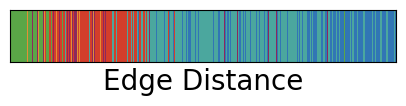

In [235]:
n_bins = 450  # Changed from bin_num
fs = 20

data_cond = data[data['condition']==cond]
labels = [clean_signal_names[s] for s in signals]+['Latent Angle (φ)', 'Edge Distance']

for i,sig in enumerate(signals+['L_theta', 'MetricDist']):
    
    # Define percentile limits
    lower_percentile = 1  
    upper_percentile = 99
    
    # Get the actual values at these percentiles
    lower_limit = data[sig].quantile(lower_percentile / 100)
    upper_limit = data[sig].quantile(upper_percentile / 100)
    
    # Filter data to this range
    data_filtered = data_cond[(data_cond[sig] >= lower_limit) & (data_cond[sig] <= upper_limit)].copy()
    
    # Create bins for the r coordinate on filtered data
    data_filtered['r_bin'] = pd.cut(data_filtered[sig], bins=n_bins, labels=False)
    
    # Sample one cell from each bin - keep the bin info
    sampled_cells = []
    for bin_idx in range(n_bins):  # Changed variable name
        bin_data = data_filtered[data_filtered['r_bin'] == bin_idx]
        if len(bin_data) > 0:
            sample = bin_data.sample(n=1, random_state=1)
            sampled_cells.append({
                'bin': bin_idx,
                'threshold_clusters': sample['threshold_clusters'].iloc[0]
            })
    
    sampled_df = pd.DataFrame(sampled_cells)
    
    # Plot the bar
    fig, ax = plt.subplots(figsize=(4, 1))
    
    for _, row in sampled_df.iterrows():
        ax.barh(0, 1, left=row['bin'], height=1, color=IIF.colmap_fates[row['threshold_clusters']])
    
    # Formatting
    ax.set_xlim(0, n_bins)
    ax.set_ylim(-0.5, 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(labels[i], fontsize=fs)
    plt.tight_layout(pad=0.5)

    if sig=='L_theta':
        plt.savefig('Fig3/barplot_fate_'+ sig+ '_' + str(len(signals)) + 'D' + '_run' + str(run)  + '.png')
    elif sig in ['pSMAD1', 'cytopERK', 'MetricDist']:
        plt.savefig('Fig3/barplot_fate_'+sig+'.png')
    else:
        plt.savefig('FigS7/barplot_fate_'+sig+'.png')
    plt.show()
    plt.close()

### Relate latent polar coordinates to signals

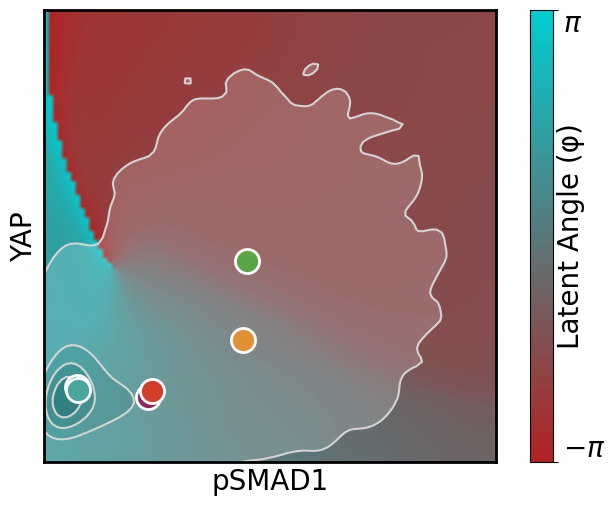

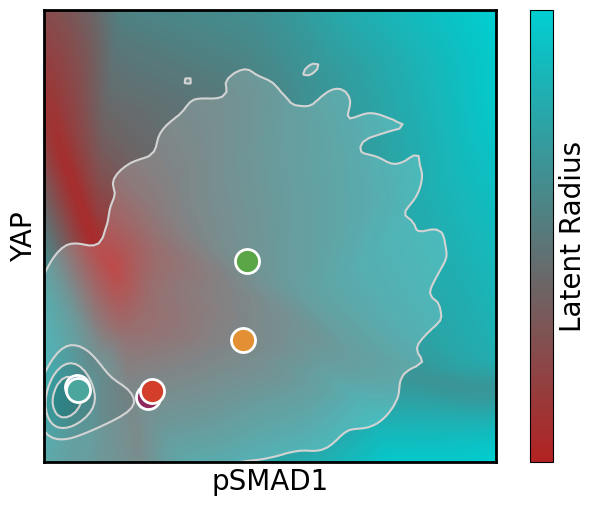

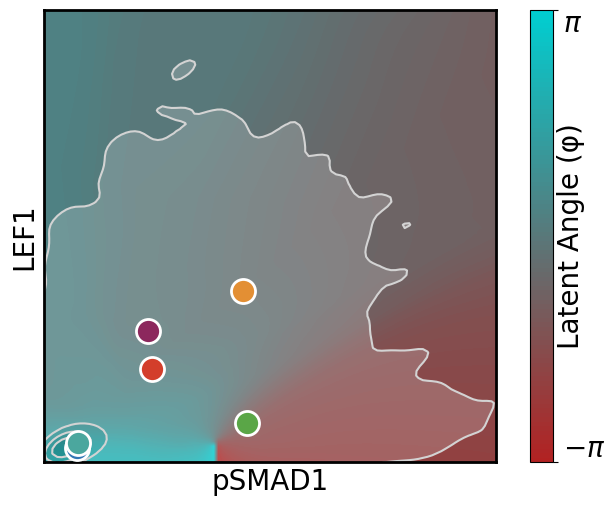

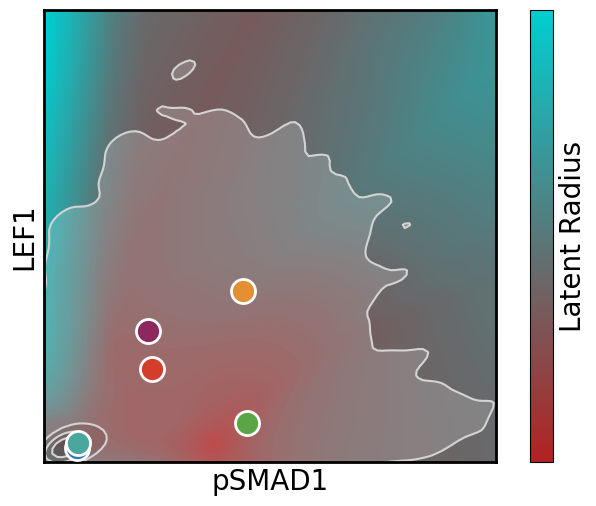

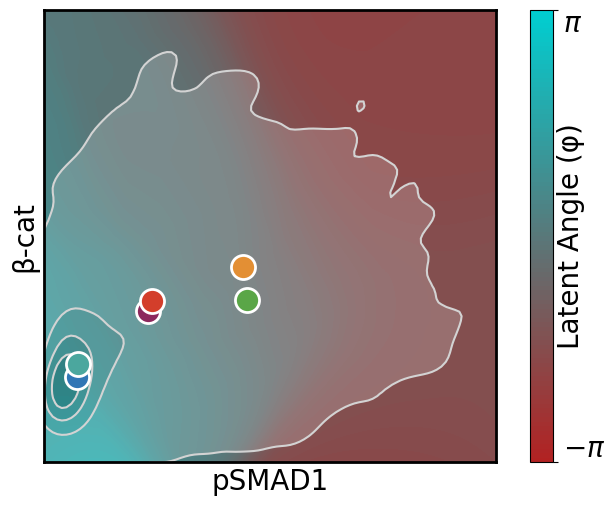

...

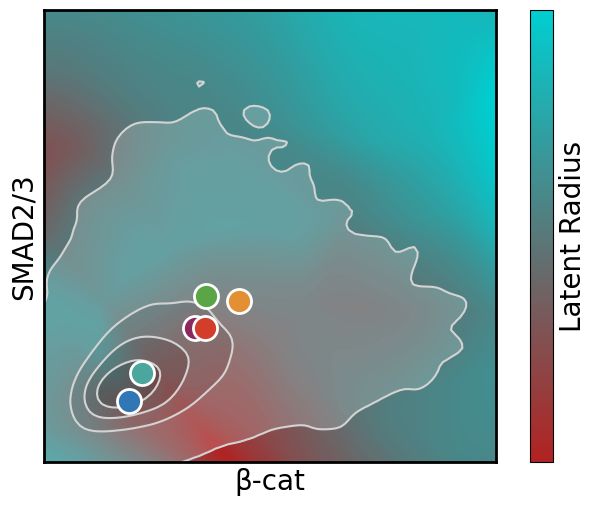

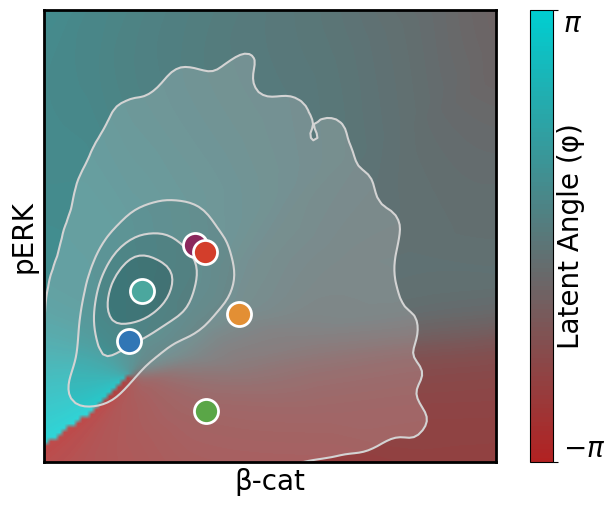

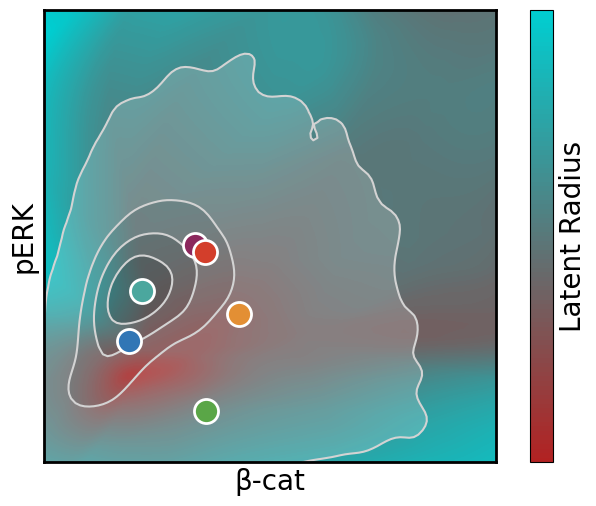

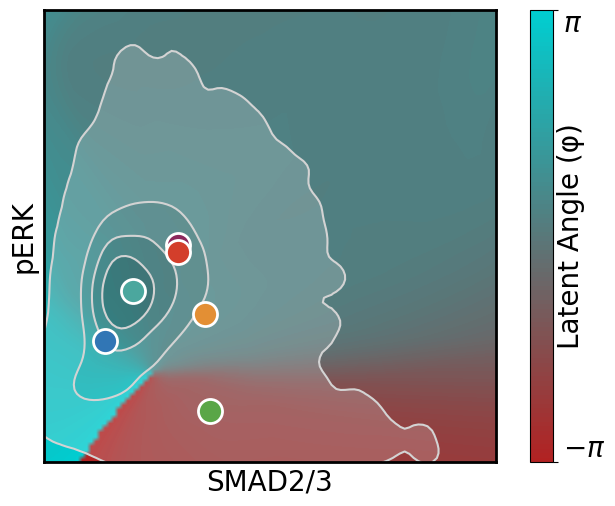

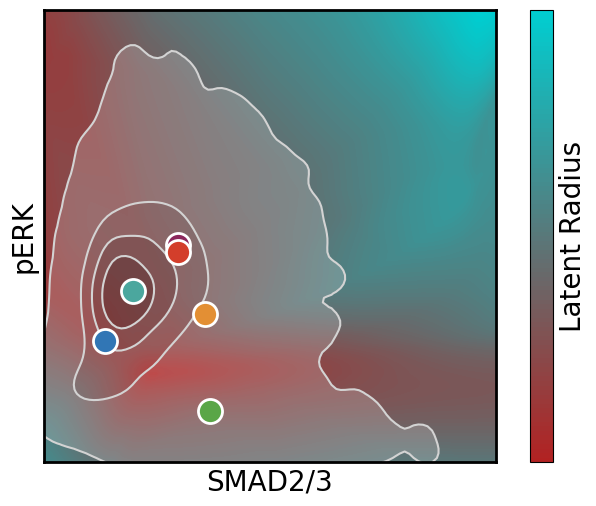

In [161]:
# calculate a smoothened average of the holdout signals over the signaling grid

signalcombos = [('pSMAD1','ncYAP'), ('pSMAD1','LEF1'), ('pSMAD1','BCat'),('pSMAD1','ncSMAD23'),  ('pSMAD1','cytopERK'), 
                ('ncYAP', 'LEF1'), ('ncYAP', 'BCat'), ('ncYAP', 'ncSMAD23'), ('ncYAP', 'cytopERK'),
                ('LEF1','BCat'), ('LEF1','ncSMAD23'), ('LEF1','cytopERK'),
                ('BCat','ncSMAD23'), ('BCat','cytopERK'),
                ('ncSMAD23','cytopERK')]

# signalcombos = [('pSMAD1','ncYAP'), ('pSMAD1','LEF1'), ('pSMAD1','ncSMAD23'),  ('pSMAD1','cytopERK'), 
#                 ('ncYAP', 'LEF1'), ('ncYAP', 'ncSMAD23'), ('ncYAP', 'cytopERK'),
#                 ('LEF1','ncSMAD23'), ('LEF1','cytopERK'),
#                 ('ncSMAD23','cytopERK')]

for (sig_i, sig_j) in signalcombos:

    n_bins = 100
    bandwidth = None
    mask = data['condition']=='B50'
    n_signals = len(signals)
    
    # Get signal ranges (use percentiles to avoid outliers)
    x_min, x_max = np.percentile(data.loc[mask,sig_i], [0.1, 99.9])
    y_min, y_max = np.percentile(data.loc[mask,sig_j], [0.1, 99.9])
    
    # Create grid
    x_grid = np.linspace(x_min, x_max, n_bins)
    y_grid = np.linspace(y_min, y_max, n_bins)
    
    # Compute adaptive bandwidth if not provided
    if bandwidth is None:
        # Use ~10% of the data range as bandwidth
        bandwidth_x = (x_max - x_min) / 10
        bandwidth_y = (y_max - y_min) / 10
    else:
        bandwidth_x = bandwidth_y = bandwidth
    
    # Holdout signal indices
    holdout_sigs = [s for s in signals if s not in (sig_i, sig_j)]
    
    # Extract holdout columns - ensure numeric
    X_holdout = data.loc[:, holdout_sigs].values
    
    # Precompute for efficiency
    X_sig_i = data[sig_i].values
    X_sig_j = data[sig_j].values
    
    grids = {}
    for sig in signals:
        grids[sig] = np.zeros((n_bins, n_bins))
    
    # For each grid point, interpolate holdout signals and compute L
    for i, x_val in enumerate(x_grid):
        for j, y_val in enumerate(y_grid):
            
            # Gaussian kernel weights
            dist_sq = ((X_sig_i - x_val) / bandwidth_x)**2 + ((X_sig_j - y_val) / bandwidth_y)**2
            weights = np.exp(-0.5 * dist_sq)
            weight_sum = weights.sum()
            
            # Skip if no data nearby
            if weight_sum < 1e-10:
                continue
            
            # Normalize weights
            weights = weights / weight_sum
            
            # Interpolate holdout signals (Nadaraya-Watson estimator)
            holdout_interp = (weights[:, np.newaxis] * X_holdout).sum(axis=0)
            
            # Construct full signal vector
            grids[sig_i][j,i] = x_val
            grids[sig_j][j,i] = y_val
            for k, hs in enumerate(holdout_sigs):
                grids[hs][j,i] = holdout_interp[k]

    #-----------------------------------------------------------------------------
    # feed the signaling grids into Sig2Fate to get latent coordinates
    siggrids = pd.DataFrame({key: grid.ravel() for key, grid in grids.items()})

    X = vib_choice.scaler_X_run.transform(siggrids)
    X = torch.FloatTensor(X).to(device)
    
    # 2D model
    model = vib_choice.model.eval() 
    with torch.no_grad():
        mu, _ = model.encode(X)
    
    L1 = mu[:, 0].cpu().numpy()
    L2 = mu[:, 1].cpu().numpy()
    
    # Standardize target
    #scaler_y = StandardScaler()
    L1_scaled = (L1 - L1mean)/L1std
    L2_scaled = (L2 - L2mean)/L1std
    
    L1_scaled = L1_scaled.reshape(n_bins,n_bins)
    L2_scaled = L2_scaled.reshape(n_bins,n_bins)

    #--------COMPUTE KDE OF DATA --------------
    
    # Create KDE in corrected polar space
    mask = data['condition']=='B50'
    values = data.loc[mask, [sig_i, sig_j]]
    kernel = sp.stats.gaussian_kde(values.T)#, bw_method=0.2)
    
    # Evaluate KDE at the actual data points (transpose needed!)
    kde_at_data = kernel(values.T)
 
    # Set vmin so that X% of data points are outside the contours
    data_percentile = 1  # Change this: 10 means 10% of data outside, 90% inside
    vmin = np.percentile(kde_at_data, data_percentile)
    
    # Evaluate KDE on the grid
    kde_grid = kernel(np.vstack([siggrids[sig_i], siggrids[sig_j]]))
    kde_grid = kde_grid.reshape(grids[sig_i].shape)  # Fixed: use .shape instead of .ravel()
    
    # Define contour levels from vmin to max
    vmax = kde_grid.max()
    levels = np.linspace(vmin, vmax, 5)
    
    # # Verify
    # fraction_inside = np.sum(kde_at_data >= vmin) / len(kde_at_data)  # Fixed: use len(kde_at_data)
    # print(f"{fraction_inside*100:.1f}% of data points are inside the contours")
    
    #--------------Compute  polar coordinates---------------
    x_centered = L1_scaled - center_x
    y_centered = L2_scaled - center_y
    r = np.sqrt(x_centered**2 + y_centered**2)
    theta_raw = np.arctan2(y_centered, x_centered)
    
    # Rotate angles so the gap is at ±π and reverse direction
    theta_corrected = -(theta_raw - gap_angle + np.pi)
    # Wrap to [-π, π]
    theta_corrected = np.arctan2(np.sin(theta_corrected), np.cos(theta_corrected))
    
    #---------------compute mean position of each fate---------------
    
    fates, fate_names = IIF.return_fates(data, thresh=thresh)
    fatemean = {}
    
    for f in fate_names:
        mask = (data['condition']=='B50') & (fates==f)
        fatemean[f] = data.loc[mask, [sig_i, sig_j]].mean()
    
    #--------------PLOT---------------
    
    for k, colorfor in {'theta':theta_corrected, 'r':r}.items():
        
        fig, ax = plt.subplots(1,1,figsize=(7,5))
        
        # Plot heatmap using imshow for smooth appearance
        extent = [x_grid[0], x_grid[-1], y_grid[0], y_grid[-1]]
        if k == 'theta':
            vmin = -np.pi
            vmax = np.pi
        elif k=='r':
            vmin = 0
            vmax = r.max()
            
        im = ax.imshow(colorfor, origin='lower', extent=extent, aspect='auto', cmap=cmap, interpolation='bilinear', vmin=vmin, vmax=vmax)
    
        # Add KDE contours
        ax.contourf(grids[sig_i], grids[sig_j], kde_grid, levels=levels, cmap='Greys', alpha=0.2)
        ax.contour(grids[sig_i], grids[sig_j], kde_grid, levels=levels, colors='lightgray', linewidths=1.5)
    
        for f in fate_names[:-1]: #-1 to remove other
            ax.scatter(fatemean[f][sig_i],fatemean[f][sig_j],color=IIF.colmap_fates[f], zorder=3, s=300, edgecolors='white',linewidths=2)
        
        ax.set_xlabel(clean_signal_names[sig_i], fontsize=fs)
        ax.set_ylabel(clean_signal_names[sig_j], fontsize=fs)
        ax.set_xticks([])
        ax.set_yticks([])
        cbar = fig.colorbar(im, ax=ax)
        
        if k=='theta':
            cbar.set_ticks([-np.pi, np.pi])
            cbar.set_ticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
            cbar.set_label('Latent Angle (φ)', fontsize=fs, rotation=90, labelpad=-35)
            tick_labels = cbar.ax.get_yticklabels()
            tick_labels[0].set_verticalalignment('bottom')
            tick_labels[1].set_verticalalignment('top')
        elif k=='r':
            cbar.set_ticks([])
            cbar.set_label('Latent Radius', fontsize=fs, rotation=90)
        
        ax.set_box_aspect(1)
        for spine in ax.spines.values():
            spine.set_linewidth(sw)
    
        plt.tight_layout(pad=0.5)
        if ((sig_i, sig_j) in [('pSMAD1','cytopERK'), ('ncYAP', 'LEF1')]) and k=='theta':
            plt.savefig('Fig3/LS_'+k+'_'+sig_i+'_'+sig_j+'_heatmap_' + str(len(signals)) + 'D_run' + str(run) + '.png')

        plt.savefig('FigS7/LS_'+k+'_'+sig_i+'_'+sig_j+'_heatmap_' + str(len(signals)) + 'D_run' + str(run) + '.png')
        plt.show()
        plt.close()